# Sistema de Alerta Temprana para la Inflación Mensual de Lima Metropolitana
**Proyecto de tesis:** *Diseño e implementación de un prototipo de alerta temprana para identificar variaciones inflacionarias mensuales en Lima Metropolitana mediante indicadores económicos.*

Autores: Gogin Cisterna, Rodrigo Alejandro · Villasante López, Bryan Jean Pierre — Asesora: Sayan Mejía, Pilar

Metodología: **CRISP-DM** (Fases 1 a 6). Este notebook implementa **todas las etapas 1-12 del documento de tesis** (sección 10.2) y es 100 % reproducible: descarga las series del BCRP, valida los supuestos, entrena y compara los modelos con validación temporal de ventana expansiva, genera el motor de alertas, prueba su funcionamiento y exporta un dashboard interactivo.

> **Cómo ejecutarlo:** `Entorno de ejecución → Ejecutar todo` (Colab) o `Run All` (Jupyter). Requiere internet para consultar la API del BCRP; si no hubiera conexión, usa la copia local guardada en `salidas_alerta_inflacion/cache_bcrp/`.

## 0. Control de cambios respecto a la versión anterior

| # | Problema detectado en la versión anterior | Corrección en esta versión |
|---|---|---|
| 1 | **Ridge, Lasso, Random Forest, Extra Trees y Gradient Boosting nunca se ejecutaban** (el bloque de ML estaba después de un `raise`, código inalcanzable); la tabla de validación mostraba `N=0, MAE=NaN` y *ganaba* SARIMA por descarte. | Función de predicción reescrita y probada. Todos los modelos producen predicciones válidas (se verifica con un `assert`). |
| 2 | XGBoost se importaba pero **nunca se entrenaba**, aunque la tesis lo propone (secciones 5.2, 8.12). | XGBoost incorporado junto con Ridge, Lasso y Random Forest. |
| 3 | La API se consultaba sin rango de fechas y **solo devolvía los últimos 60 meses** (Nov-2021 a Oct-2026): ~47 observaciones para entrenar. | Se consulta desde 2003; ≈ 260 observaciones mensuales útiles. El inicio es un parámetro (`FECHA_INICIO`). |
| 4 | Se asumía un rezago de 1 mes **también para el IPC**, lo que contradice la tesis (*"información disponible hasta t para estimar t+1"*) y desperdiciaba el último IPC publicado. | Calendario de publicación explícito (`DIA_PUB`, `DIA_EMISION`): el rezago de cada variable **se deriva** de su fecha de publicación. |
| 5 | El código `PN01311PM` es solo *Inflación no subyacente – Servicios Públicos*, pero se rotulaba como "inflación no subyacente". | Se incorporan `PN01307PM` (no subyacente total) y `PN01295PM` (subyacente) y se conserva `PN01311PM` con su nombre correcto. |
| 6 | Faltaban la **tasa de referencia** y el **tipo de cambio** (sección 6.3 y 9.5 de la tesis). | Se incorporan (series mensuales oficiales `PD04722MM` y `PN01207PM`; los códigos diarios devuelven solo `n.d.`). |
| 7 | Umbrales P33/P67 calculados **una sola vez**; la tesis exige recalcularlos **en cada ventana** (secciones 5.2, 8.17). | Umbrales recalculados en cada origen del *walk-forward*. |
| 8 | No existían métricas de clasificación ni las pruebas del motor de alertas (Etapas 9 y 10). | Accuracy, precision, recall, F1, matriz de confusión (énfasis en *Alta*) y batería de pruebas de umbrales, límites y consistencia. |
| 9 | Conclusiones del EDA **escritas a mano** con cifras que no coincidían con las salidas (p. ej. ADF = -3.04 vs. -5.16 real; correlaciones 0.54 y 0.01 sin verificar). | Todas las interpretaciones se generan **a partir de los resultados calculados**. |
| 10 | Sin evaluación de supuestos completa (Etapa 4), sin prueba de significancia frente a la persistencia (H₀/H₁), sin interpretabilidad, sin dashboard, exportación ni registro mensual de predicciones. | Secciones 5.8, 10-18 nuevas. |
| 11 | SARIMAX "multi-paso" con *exógenas futuras* de apariencia correcta pero ajena al diseño de la tesis. | Los modelos ARIMA/SARIMA (referencia metodológica, sección 8.13) pronostican 1 paso con la historia hasta el origen. |

---
# FASE 1 — Comprensión del Negocio

## 1.1 Contexto y problema
La inflación mensual puede variar de forma importante incluso cuando la inflación interanual está dentro del rango meta del BCRP (1 %-3 %). Las series oficiales están dispersas en distintas plataformas y fechas de publicación; el problema es **la ausencia de un prototipo académico reproducible que, con datos oficiales disponibles hasta el mes actual, estime y clasifique la variación inflacionaria mensual del mes siguiente** con validación temporal.

## 1.2 Objetivo
Estimar $\pi_{t+1}$ (variación porcentual mensual del IPC de Lima Metropolitana, serie `PN01364PM`) usando **solo** la información disponible en el origen $t$, y traducir la estimación a una alerta **Baja / Media / Alta** con umbrales P33 y P67 calculados únicamente con datos de entrenamiento.

## 1.3 Formulación analítica
$$X_t \rightarrow \pi_{t+1}, \qquad \pi_t = \frac{IPC_t - IPC_{t-1}}{IPC_{t-1}}\times 100$$

* **Origen $t$:** primeros días del mes $t+1$, una vez publicado el IPC del mes $t$ (el INEI lo publica el día 1).
* **Objetivo:** inflación mensual del mes $t+1$.

## 1.4 Criterios de éxito (se verifican al final, sección 18)
1. Los modelos de ML superan a la persistencia (MAE y RMSE).
2. Metodología sin fuga de información (validación de ventana expansiva y pruebas automáticas).
3. Errores aceptables (MAE, RMSE) frente a las líneas base.
4. Clasificación correcta de los niveles de alerta (énfasis en *Alta*).
5. Interpretabilidad de los indicadores influyentes.
6. Dashboard interactivo.

## 1.5 Hipótesis
* **H₀:** los modelos de ML no mejoran significativamente al modelo de persistencia.
* **H₁:** los modelos de ML mejoran el desempeño predictivo respecto a la persistencia.

Se contrastan con la prueba de **Diebold-Mariano** (con corrección de Harvey-Leybourne-Newbold) en la sección 12.4.

## 1.6 Trazabilidad con el documento de tesis

| Etapa de la tesis (10.2) | Dónde se implementa |
|---|---|
| 1. Recolección de datos | Sección 3 |
| 2. Integración y depuración | Sección 6 |
| 3. Análisis exploratorio | Sección 5 |
| 4. Evaluación de supuestos | Sección 5.8 (y 12.5 para generalización) |
| 5. Ingeniería de variables | Sección 7 |
| 6. Variable objetivo | Sección 7.1-7.2 |
| 7. Modelamiento | Secciones 9-10 |
| 8. Validación temporal | Secciones 8 y 11 |
| 9. Evaluación de modelos | Sección 12 |
| 10. Validación del motor de alertas | Sección 14.3 |
| 11. Generación de alertas | Secciones 14-15 |
| 12. Dashboard | Sección 17 |

---
# FASE 2 — Comprensión de los Datos
## 2. Configuración

In [ ]:
import warnings, json, sys, subprocess
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import requests
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy import stats
from scipy.signal import periodogram

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.stattools import pacf as _pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, breaks_cusumolsresid

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix)
from xgboost import XGBRegressor
import time
import shap

try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
except ImportError:                                    # entorno sin plotly
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "plotly"])
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

# Usa el almacén de certificados del sistema operativo (la cadena SSL del BCRP no siempre se valida
# con el almacén de Python en Windows). La verificación SSL NO se desactiva.
try:
    import truststore; truststore.inject_into_ssl()
except ImportError:
    pass

# ------------------------------------------------------------------
# PARÁMETROS DEL EXPERIMENTO (todos los supuestos en un solo lugar)
# ------------------------------------------------------------------
SEED          = 993
FECHA_INICIO  = "2004-01"   # inicio de la muestra (la tasa de referencia existe desde 2003-09)
N_VAL         = 36          # meses de validación (selección de modelo)
N_TEST        = 24          # meses de prueba final (mismo horizonte de 24 meses de Flores y Grandez, 2024)
MIN_TRAIN     = 60          # mínimo de meses para entrenar el primer modelo
Q_BAJO, Q_ALTO = 0.33, 0.67 # percentiles P33 y P67 del motor de alertas
DIA_EMISION   = 5           # día del mes t+1 en que se emite la alerta
N_SIMULACIONES = 20_000     # remuestreo de errores para el intervalo predictivo
NIVELES = ["Baja", "Media", "Alta"]

np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})

OUT = Path("salidas_alerta_inflacion"); OUT.mkdir(exist_ok=True)
CACHE = OUT / "cache_bcrp"; CACHE.mkdir(exist_ok=True)

def linea(n=80, s="-"):
    print(s * n)

print(f"Parámetros cargados · semilla={SEED} · carpeta de salidas: {OUT.resolve()}")

Parámetros cargados · semilla=993 · carpeta de salidas: C:\Users\LENOVO\Documents\GLOBAL\octubre\salidas_alerta_inflacion


---
## 3. Recolección de Datos (Etapa 1)

Se usa la API pública **BCRPData**. A diferencia de la versión anterior se especifica el **rango de fechas** (`/json/inicio/fin/esp`); sin él la API devuelve solo los últimos 60 meses.

### 3.1 Catálogo de series y calendario de publicación (supuesto de disponibilidad)

El **rezago de disponibilidad** de cada variable no se fija a mano: se *deriva* comparando su día estimado de publicación (`DIA_PUB`) con el día en que se emite la alerta (`DIA_EMISION`). Si una variable se publica después de la emisión, solo se puede usar con un mes de retraso. **Nota sobre la tasa de referencia:** el código diario `PD12301MD` citado en la bibliografía de la tesis (y las series diarias de tipo de cambio) devuelven únicamente `n.d.` (sin datos) al consultarse por la API; se usan las series mensuales oficiales equivalentes `PD04722MM` (tasa de referencia) y `PN01207PM` (tipo de cambio interbancario promedio del mes). Los días de publicación de IPM y expectativas son **supuestos conservadores** que deben verificarse con los calendarios oficiales (es un parámetro editable).

In [ ]:
# Día del mes t+1 en que se estima disponible el dato del mes t  (SUPUESTOS EDITABLES)
CATALOGO = {
    "ipc":             dict(codigo="PN01364PM", desc="Inflación mensual IPC Lima Metropolitana", unidad="% var. mensual", freq="M", agg=None,   fuente="BCRP / INEI", dia_pub=1),
    "subyacente":      dict(codigo="PN01295PM", desc="Inflación subyacente",                      unidad="% var. mensual", freq="M", agg=None,   fuente="BCRP / INEI", dia_pub=1),
    "no_subyacente":   dict(codigo="PN01307PM", desc="Inflación no subyacente (total)",           unidad="% var. mensual", freq="M", agg=None,   fuente="BCRP / INEI", dia_pub=1),
    "serv_publicos":   dict(codigo="PN01311PM", desc="Inflación no subyacente: servicios públicos", unidad="% var. mensual", freq="M", agg=None, fuente="BCRP / INEI", dia_pub=1),
    "ipm":             dict(codigo="PN01286PM", desc="Índice de precios al por mayor (var. mensual)", unidad="% var. mensual", freq="M", agg=None, fuente="BCRP / INEI", dia_pub=15),
    "expectativa_12m": dict(codigo="PD12912AM", desc="Expectativa de inflación a 12 meses",       unidad="%",              freq="M", agg=None,   fuente="BCRP (encuesta)", dia_pub=15),
    "tasa_ref":        dict(codigo="PD04722MM", desc="Tasa de referencia de la política monetaria (mensual)", unidad="%", freq="M", agg=None, fuente="BCRP", dia_pub=1),
    "tipo_cambio":     dict(codigo="PN01207PM", desc="Tipo de cambio interbancario, promedio del mes", unidad="S/ por US$", freq="M", agg=None, fuente="BCRP", dia_pub=1),
}
# Variable derivada
DERIVADAS = {"tipo_cambio_var": dict(desc="Variación % mensual del tipo de cambio", unidad="% var. mensual", base="tipo_cambio", dia_pub=1,
                                    transf="pct_change(tipo_cambio)*100")}

DIA_PUB = {k: v["dia_pub"] for k, v in CATALOGO.items()}
DIA_PUB.update({k: v["dia_pub"] for k, v in DERIVADAS.items()})
LAG_DISP = {k: 0 if d <= DIA_EMISION else 1 for k, d in DIA_PUB.items()}

pd.DataFrame({"día publicación (t+1)": DIA_PUB, "rezago de disponibilidad (meses)": LAG_DISP})

,día publicación (t+1),rezago de disponibilidad (meses)
ipc,1,0
subyacente,1,0
no_subyacente,1,0
serv_publicos,1,0
ipm,15,1
expectativa_12m,15,1
tasa_ref,1,0
tipo_cambio,1,0
tipo_cambio_var,1,0


In [ ]:
MESES = {"Ene":1,"Feb":2,"Mar":3,"Abr":4,"May":5,"Jun":6,"Jul":7,"Ago":8,"Set":9,"Sep":9,"Oct":10,"Nov":11,"Dic":12}

def parsear_fecha(texto):
    """'Nov.2021' -> 2021-11-01 ;  '01.Ene.03' -> 2003-01-01"""
    p = texto.split(".")
    if len(p) == 2:
        return pd.Timestamp(int(p[1]), MESES[p[0]], 1)
    d, m, a = p
    a = int(a); a += 2000 if a < 50 else 1900
    return pd.Timestamp(a, MESES[m], int(d))

def descargar_serie(codigo, inicio="2003-1"):
    """Consulta BCRPData. Guarda una copia local y la usa si la API no responde."""
    hoy = pd.Timestamp.today()
    url = (f"https://estadisticas.bcrp.gob.pe/estadisticas/series/api/"
           f"{codigo}/json/{inicio}/{hoy.year}-{hoy.month}/esp")
    archivo = CACHE / f"{codigo}.json"
    try:
        r = requests.get(url, timeout=60)          # la verificación SSL permanece activa
        r.raise_for_status()
        data = r.json()
        archivo.write_text(json.dumps(data), encoding="utf-8")
        origen = "API"
    except Exception as e:
        if archivo.exists():
            data = json.loads(archivo.read_text(encoding="utf-8")); origen = "CACHE"
            print(f"  ! {codigo}: sin conexión ({type(e).__name__}); se usa copia local")
        else:
            raise RuntimeError(f"No se pudo descargar {codigo} y no hay copia local") from e
    return data, origen

def json_a_serie(data):
    filas = {parsear_fecha(p["name"]): p["values"][0] for p in data["periods"]}
    s = pd.to_numeric(pd.Series(filas), errors="coerce")        # 'n.d.' -> NaN
    s.index = pd.DatetimeIndex(s.index)
    return s.sort_index()

series_m, fichas = {}, []
fecha_descarga = datetime.now().strftime("%Y-%m-%d %H:%M")
for nombre, cfg in CATALOGO.items():
    data, origen = descargar_serie(cfg["codigo"])
    s = json_a_serie(data)
    if s.notna().sum() == 0:
        raise ValueError(f"La serie {cfg['codigo']} ({nombre}) no tiene datos publicados; verifique el código en BCRPData")
    nombre_oficial = data["config"]["series"][0]["name"]
    if cfg["freq"] == "D":                       # serie diaria -> mensual (agregación causal)
        s = s.resample("MS").agg(cfg["agg"])
    series_m[nombre] = s
    fichas.append({"variable": nombre, "código": cfg["codigo"], "origen": origen,
                   "primer dato": s.first_valid_index().strftime("%Y-%m"),
                   "último dato": s.last_valid_index().strftime("%Y-%m"),
                   "nº meses": s.notna().sum(), "nombre oficial BCRP": nombre_oficial[-70:]})
    print(f"{nombre:16s} {cfg['codigo']}  [{origen}]  {s.first_valid_index():%Y-%m} -> {s.last_valid_index():%Y-%m}")

pd.DataFrame(fichas)

ipc              PN01364PM  [API]  2003-01 -> 2026-10


subyacente       PN01295PM  [API]  2003-01 -> 2026-10


no_subyacente    PN01307PM  [API]  2003-01 -> 2026-10


serv_publicos    PN01311PM  [API]  2003-01 -> 2026-10


ipm              PN01286PM  [API]  2003-01 -> 2026-10


expectativa_12m  PD12912AM  [API]  2003-01 -> 2026-10


tasa_ref         PD04722MM  [API]  2003-09 -> 2026-10


tipo_cambio      PN01207PM  [API]  2003-01 -> 2026-10


,variable,código,origen,primer dato,último dato,nº meses,nombre oficial BCRP
0,ipc,PN01364PM,API,2003-01,2026-10,286,no transables (variación porcentual) - Índice ...
1,subyacente,PN01295PM,API,2003-01,2026-10,286,clasificación sectorial (variación porcentual...
2,no_subyacente,PN01307PM,API,2003-01,2026-10,286,asificación sectorial (variación porcentual) -...
3,serv_publicos,PN01311PM,API,2003-01,2026-10,286,(variación porcentual) - Inflación No Subyace...
4,ipm,PN01286PM,API,2003-01,2026-10,286,ios Lima Metropolitana (var% mensual) - Índice...
5,expectativa_12m,PD12912AM,API,2003-01,2026-10,286,Expectativas macroeconómicas - Expectativa de ...
6,tasa_ref,PD04722MM,API,2003-09,2026-10,278,Banco Central de Reserva - Tasa de Referencia ...
7,tipo_cambio,PN01207PM,API,2003-01,2026-10,286,cambio - promedio del periodo (S/ por US$) - ...


### 3.2 INEI
El INEI es la fuente primaria del IPC; el BCRP replica la serie con mismo valor y mejor acceso programático, por lo que esta versión usa la API del BCRP para toda la cadena de datos (decisión documentada en la matriz de recolección, sección 6.5). Si se desea incorporar un indicador exclusivo del INEI, basta añadir una entrada a `CATALOGO`.

### 3.3 Diccionario de variables

In [ ]:
diccionario = pd.DataFrame(
    [{"variable": k, "código": v["codigo"], "descripción": v["desc"], "unidad": v["unidad"],
      "fuente": v["fuente"], "día publ. (t+1)": v["dia_pub"], "rezago uso (meses)": LAG_DISP[k]}
     for k, v in CATALOGO.items()] +
    [{"variable": k, "código": f"derivada de {v['base']}", "descripción": v["desc"], "unidad": v["unidad"],
      "fuente": "Elaboración propia", "día publ. (t+1)": v["dia_pub"], "rezago uso (meses)": LAG_DISP[k]}
     for k, v in DERIVADAS.items()]).set_index("variable")
diccionario

,código,descripción,unidad,fuente,día publ. (t+1),rezago uso (meses)
variable,,,,,,
ipc,PN01364PM,Inflación mensual IPC Lima Metropolitana,% var. mensual,BCRP / INEI,1,0
subyacente,PN01295PM,Inflación subyacente,% var. mensual,BCRP / INEI,1,0
no_subyacente,PN01307PM,Inflación no subyacente (total),% var. mensual,BCRP / INEI,1,0
serv_publicos,PN01311PM,Inflación no subyacente: servicios públicos,% var. mensual,BCRP / INEI,1,0
ipm,PN01286PM,Índice de precios al por mayor (var. mensual),% var. mensual,BCRP / INEI,15,1
expectativa_12m,PD12912AM,Expectativa de inflación a 12 meses,%,BCRP (encuesta),15,1
tasa_ref,PD04722MM,Tasa de referencia de la política monetaria (m...,%,BCRP,1,0
tipo_cambio,PN01207PM,"Tipo de cambio interbancario, promedio del mes",S/ por US$,BCRP,1,0
tipo_cambio_var,derivada de tipo_cambio,Variación % mensual del tipo de cambio,% var. mensual,Elaboración propia,1,0


### 3.4 Consolidación inicial

In [ ]:
df_raw = pd.concat(series_m, axis=1)
df_raw["tipo_cambio_var"] = df_raw["tipo_cambio"].pct_change() * 100
df_raw = df_raw.loc[FECHA_INICIO:].copy()
df_raw.index.name = "fecha"

linea(); print("CONSOLIDACIÓN INICIAL")
print(f"Dimensiones: {df_raw.shape[0]} meses × {df_raw.shape[1]} variables")
print(f"Rango: {df_raw.index.min():%Y-%m} → {df_raw.index.max():%Y-%m}")
display(df_raw.tail())

--------------------------------------------------------------------------------
CONSOLIDACIÓN INICIAL
Dimensiones: 274 meses × 9 variables
Rango: 2004-01 → 2026-10


,ipc,subyacente,no_subyacente,serv_publicos,ipm,expectativa_12m,tasa_ref,tipo_cambio,tipo_cambio_var
fecha,,,,,,,,,
2026-06-01,0.2288,0.1760,0.3375,0.0504,-0.9569,2.8250,4.2500,3.4060,-0.8533
2026-07-01,0.2856,0.2397,0.3793,-0.1029,0.5480,3.0088,4.2500,3.4002,-0.1684
2026-08-01,0.0668,0.1172,-0.0353,1.1854,1.2204,3.0500,4.2500,3.3630,-1.0963
2026-09-01,0.1173,0.1383,0.0741,0.1282,0.5739,3.0875,4.2500,3.3791,0.4804
2026-10-01,0.5715,0.2587,1.2105,-0.6815,0.7384,3.0542,4.2500,3.4421,1.8629


---
## 4. Exploración Inicial de Datos
### 4.1 Estructura, tipos, nulos, duplicados y calidad

In [ ]:
linea(); print("TIPOS DE DATOS"); df_raw.info()
linea(); print("VALORES FALTANTES")
nulos = pd.DataFrame({"nulos": df_raw.isna().sum(), "%": df_raw.isna().mean() * 100,
                      "primer dato": [df_raw[c].first_valid_index() for c in df_raw],
                      "último dato": [df_raw[c].last_valid_index() for c in df_raw]})
display(nulos)
linea(); print("DUPLICADOS")
print("Fechas duplicadas:", int(df_raw.index.duplicated().sum()),
      "| filas completamente duplicadas:", int(df_raw.duplicated().sum()))
linea(); print("RESUMEN ESTADÍSTICO"); display(df_raw.describe().T)

--------------------------------------------------------------------------------
TIPOS DE DATOS
<class 'pandas.DataFrame'>
DatetimeIndex: 274 entries, 2004-01-01 to 2026-10-01
Freq: MS
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ipc              274 non-null    float64
 1   subyacente       274 non-null    float64
 2   no_subyacente    274 non-null    float64
 3   serv_publicos    274 non-null    float64
 4   ipm              274 non-null    float64
 5   expectativa_12m  274 non-null    float64
 6   tasa_ref         274 non-null    float64
 7   tipo_cambio      274 non-null    float64
 8   tipo_cambio_var  274 non-null    float64
dtypes: float64(9)
memory usage: 21.4 KB
--------------------------------------------------------------------------------
VALORES FALTANTES


,nulos,%,primer dato,último dato
ipc,0,0.0000,2004-01-01,2026-10-01
subyacente,0,0.0000,2004-01-01,2026-10-01
no_subyacente,0,0.0000,2004-01-01,2026-10-01
serv_publicos,0,0.0000,2004-01-01,2026-10-01
ipm,0,0.0000,2004-01-01,2026-10-01
expectativa_12m,0,0.0000,2004-01-01,2026-10-01
tasa_ref,0,0.0000,2004-01-01,2026-10-01
tipo_cambio,0,0.0000,2004-01-01,2026-10-01
tipo_cambio_var,0,0.0000,2004-01-01,2026-10-01


--------------------------------------------------------------------------------
DUPLICADOS
Fechas duplicadas: 0 | filas completamente duplicadas: 0
--------------------------------------------------------------------------------
RESUMEN ESTADÍSTICO


,count,mean,std,min,25%,50%,75%,max
ipc,274.0000,0.2654,0.3452,-0.5280,0.0385,0.2276,0.4426,2.3787
subyacente,274.0000,0.2506,0.1867,-0.0558,0.1318,0.2020,0.3213,0.9945
no_subyacente,274.0000,0.2927,0.7944,-1.6467,-0.1602,0.2419,0.6874,5.8193
serv_publicos,274.0000,0.1617,0.9236,-3.5401,-0.1606,0.0631,0.4900,7.0106
ipm,274.0000,0.2179,0.5930,-1.5480,-0.1329,0.1869,0.4986,3.1078
expectativa_12m,274.0000,2.7721,0.6940,1.4000,2.3829,2.6083,2.9865,5.3500
tasa_ref,274.0000,3.8212,1.6729,0.2500,2.8125,4.1250,4.5000,7.7500
tipo_cambio,274.0000,3.2569,0.3674,2.5522,2.9135,3.2738,3.4708,4.1081
tipo_cambio_var,274.0000,0.0057,1.3313,-3.7033,-0.6346,-0.1157,0.6820,4.1350


**Tratamiento de faltantes (decisión explícita y causal):**
* `tasa_ref`: la tasa de referencia es constante entre decisiones del BCRP; los meses sin dato se completan con el **último valor conocido** (*forward-fill*, usa solo el pasado → no hay fuga).
* Las demás variables no se imputan: si falta un dato dentro de la muestra se detiene el proceso (no se imputa silenciosamente).

In [ ]:
df_raw["tasa_ref"] = df_raw["tasa_ref"].ffill()

# Los meses finales aún no publicados (p. ej. IPM del último mes) pueden estar vacíos: es normal y
# se gestiona con el rezago de disponibilidad. Los huecos INTERNOS no se permiten.
ultimo_ipc = df_raw["ipc"].last_valid_index()
internos = df_raw.loc[:ultimo_ipc].drop(columns="tipo_cambio_var").isna().sum()
internos = internos[internos > 0]
print("Último IPC publicado:", f"{ultimo_ipc:%Y-%m}")
assert internos.empty or internos.drop(["ipm", "expectativa_12m"], errors="ignore").empty, \
    f"Hay faltantes internos que requieren revisión:\n{internos}"
if not internos.empty:
    print("Faltantes en el tramo final (aún no publicados):\n", internos)

df_base = df_raw.loc[:ultimo_ipc].copy()
df_base = df_base.asfreq("MS")
assert df_base["ipc"].notna().all()
print(f"Base de trabajo: {df_base.index.min():%Y-%m} → {df_base.index.max():%Y-%m}  ({len(df_base)} meses)")

Último IPC publicado: 2026-10
Base de trabajo: 2004-01 → 2026-10  (274 meses)


---
## 5. Análisis Exploratorio de Datos (Etapa 3)

> **Nota metodológica:** el EDA es descriptivo y usa la muestra completa; ninguno de sus resultados alimenta a los modelos. Las únicas excepciones (umbrales y correlaciones con el objetivo) se calculan **solo con el tramo de entrenamiento** para no contaminar la selección de variables.

Primero se define el tramo de entrenamiento inicial (todo lo anterior al periodo de validación) para esas excepciones.

In [ ]:
n_total = len(df_base)
fecha_corte_val = df_base.index[-(N_VAL + N_TEST) - 1]      # último mes antes de validación
ipc_train_eda = df_base.loc[:fecha_corte_val, "ipc"]
P33_eda, P67_eda = ipc_train_eda.quantile(Q_BAJO), ipc_train_eda.quantile(Q_ALTO)
print(f"Tramo de entrenamiento inicial (EDA): hasta {fecha_corte_val:%Y-%m}  ·  P33={P33_eda:.3f}%  P67={P67_eda:.3f}%")

Tramo de entrenamiento inicial (EDA): hasta 2021-10  ·  P33=0.111%  P67=0.347%

### 5.1 Evolución histórica

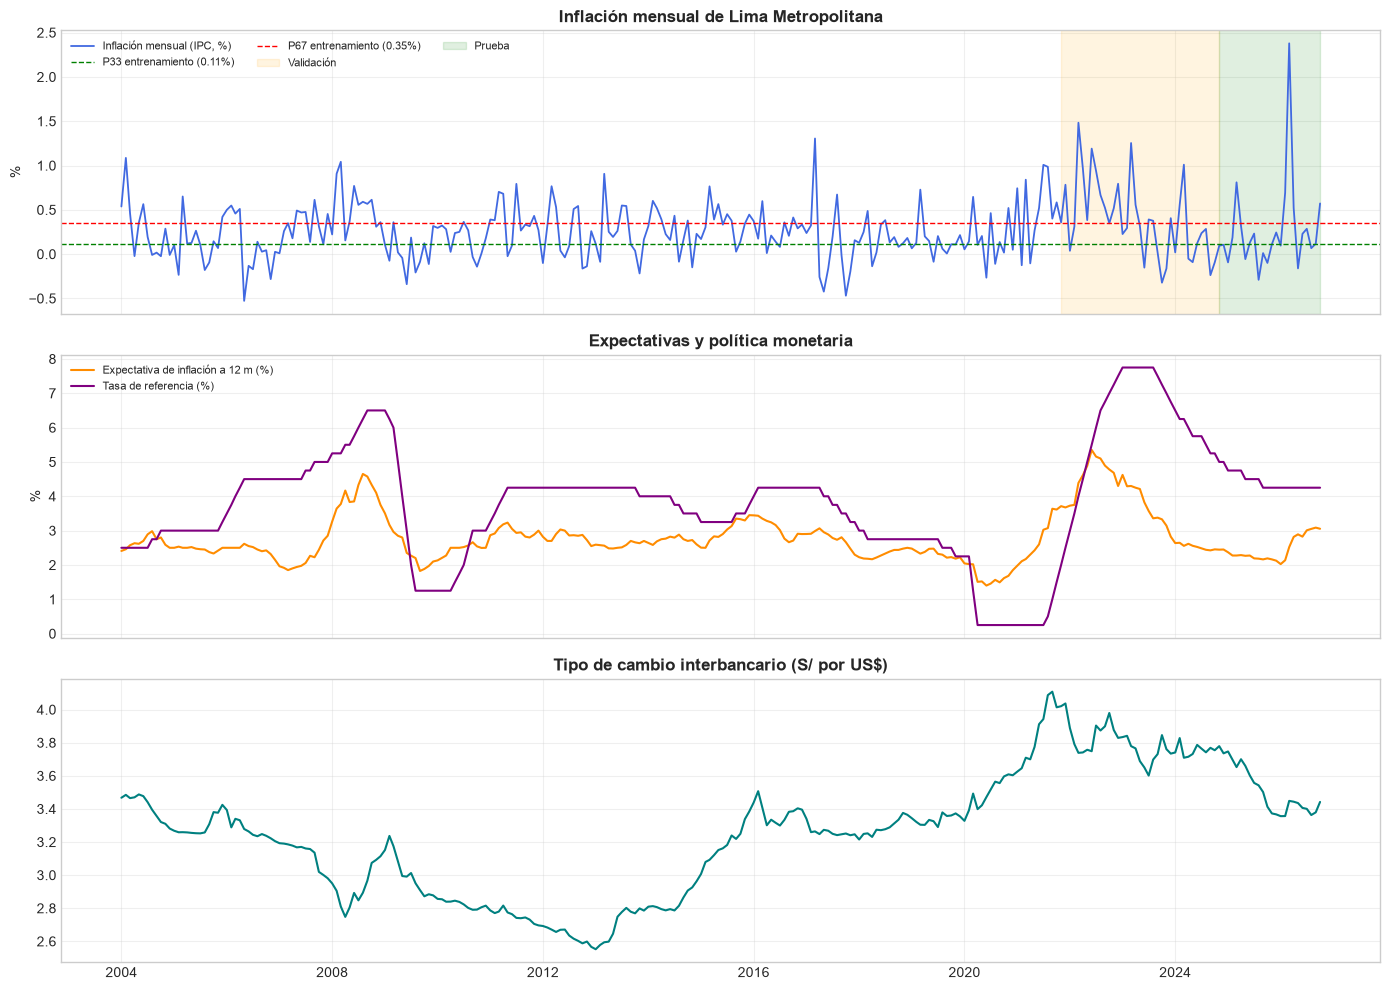

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
ax[0].plot(df_base.index, df_base["ipc"], color="royalblue", lw=1.3, label="Inflación mensual (IPC, %)")
ax[0].axhline(P33_eda, color="green", ls="--", lw=1, label=f"P33 entrenamiento ({P33_eda:.2f}%)")
ax[0].axhline(P67_eda, color="red", ls="--", lw=1, label=f"P67 entrenamiento ({P67_eda:.2f}%)")
ax[0].axvspan(df_base.index[-(N_VAL + N_TEST)], df_base.index[-N_TEST], color="orange", alpha=.12, label="Validación")
ax[0].axvspan(df_base.index[-N_TEST], df_base.index[-1], color="green", alpha=.12, label="Prueba")
ax[0].set_title("Inflación mensual de Lima Metropolitana"); ax[0].legend(ncol=3, fontsize=8); ax[0].set_ylabel("%")
ax[1].plot(df_base.index, df_base["expectativa_12m"], color="darkorange", label="Expectativa de inflación a 12 m (%)")
ax[1].plot(df_base.index, df_base["tasa_ref"], color="purple", label="Tasa de referencia (%)")
ax[1].set_title("Expectativas y política monetaria"); ax[1].legend(fontsize=8); ax[1].set_ylabel("%")
ax[2].plot(df_base.index, df_base["tipo_cambio"], color="teal"); ax[2].set_title("Tipo de cambio interbancario (S/ por US$)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 5.2 Distribución de la inflación mensual

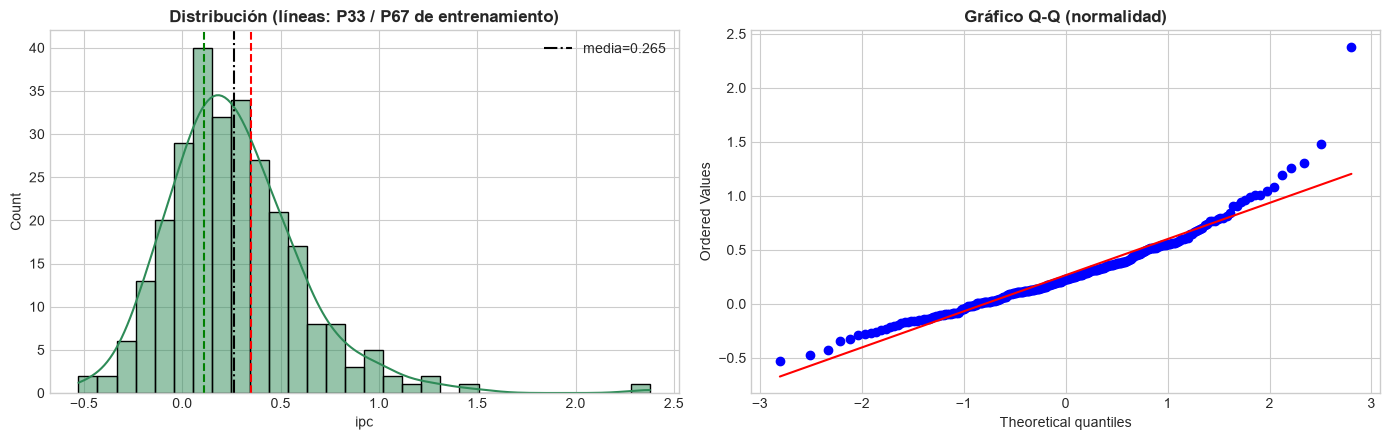

Asimetría=1.34 · Curtosis exceso=5.19 · mín=-0.53% (2006-05) · máx=2.38% (2026-03)
→ Una curtosis alta indica colas pesadas: conviene reportar MAE junto con RMSE (que penaliza más los extremos).


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df_base["ipc"], kde=True, bins=30, color="seagreen", ax=ax[0])
ax[0].axvline(P33_eda, color="green", ls="--"); ax[0].axvline(P67_eda, color="red", ls="--")
ax[0].axvline(df_base["ipc"].mean(), color="k", ls="-.", label=f"media={df_base['ipc'].mean():.3f}")
ax[0].set_title("Distribución (líneas: P33 / P67 de entrenamiento)"); ax[0].legend()
stats.probplot(df_base["ipc"], dist="norm", plot=ax[1]); ax[1].set_title("Gráfico Q-Q (normalidad)")
plt.tight_layout(); plt.show()
d = df_base["ipc"]
print(f"Asimetría={d.skew():.2f} · Curtosis exceso={d.kurt():.2f} · mín={d.min():.2f}% ({d.idxmin():%Y-%m}) · máx={d.max():.2f}% ({d.idxmax():%Y-%m})")
print("→ Una curtosis alta indica colas pesadas: conviene reportar MAE junto con RMSE (que penaliza más los extremos).")

### 5.3 Tendencia y volatilidad

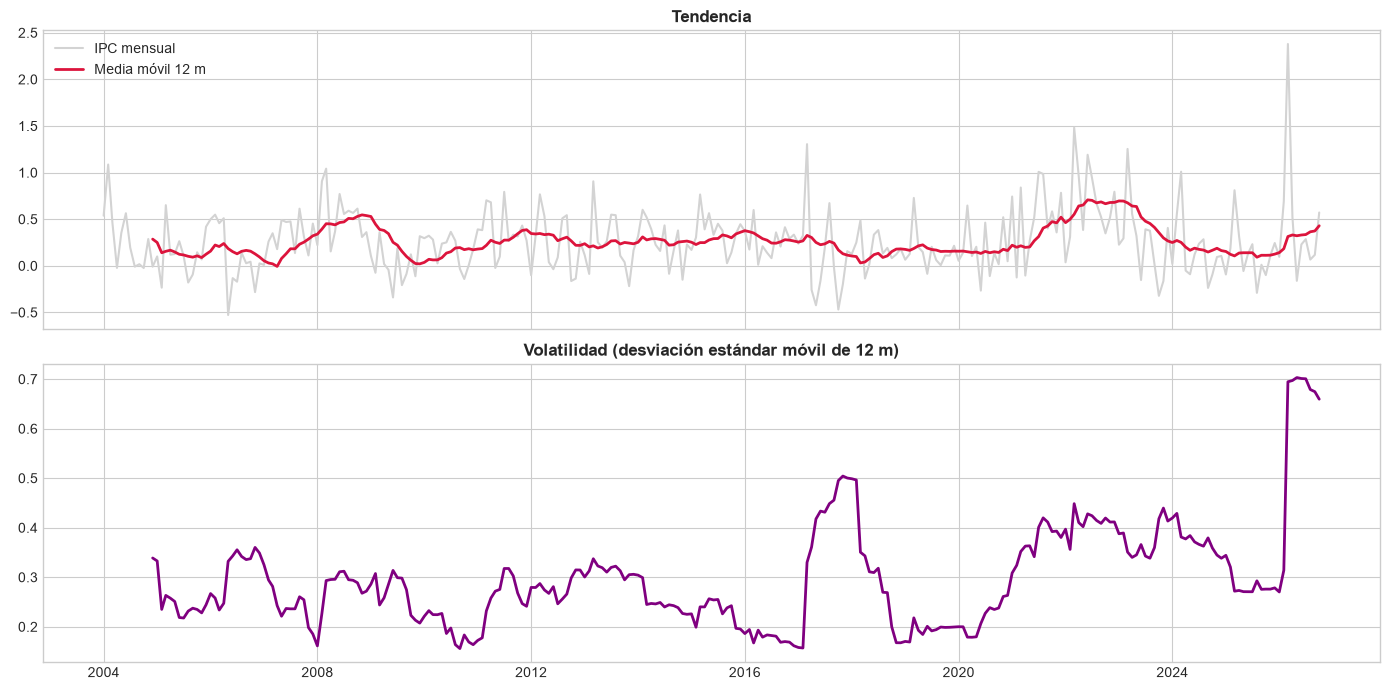

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].plot(df_base.index, df_base["ipc"], color="lightgray", label="IPC mensual")
ax[0].plot(df_base.index, df_base["ipc"].rolling(12).mean(), color="crimson", lw=2, label="Media móvil 12 m")
ax[0].legend(); ax[0].set_title("Tendencia")
ax[1].plot(df_base.index, df_base["ipc"].rolling(12).std(), color="purple", lw=2)
ax[1].set_title("Volatilidad (desviación estándar móvil de 12 m)")
plt.tight_layout(); plt.show()

### 5.4 Estacionalidad

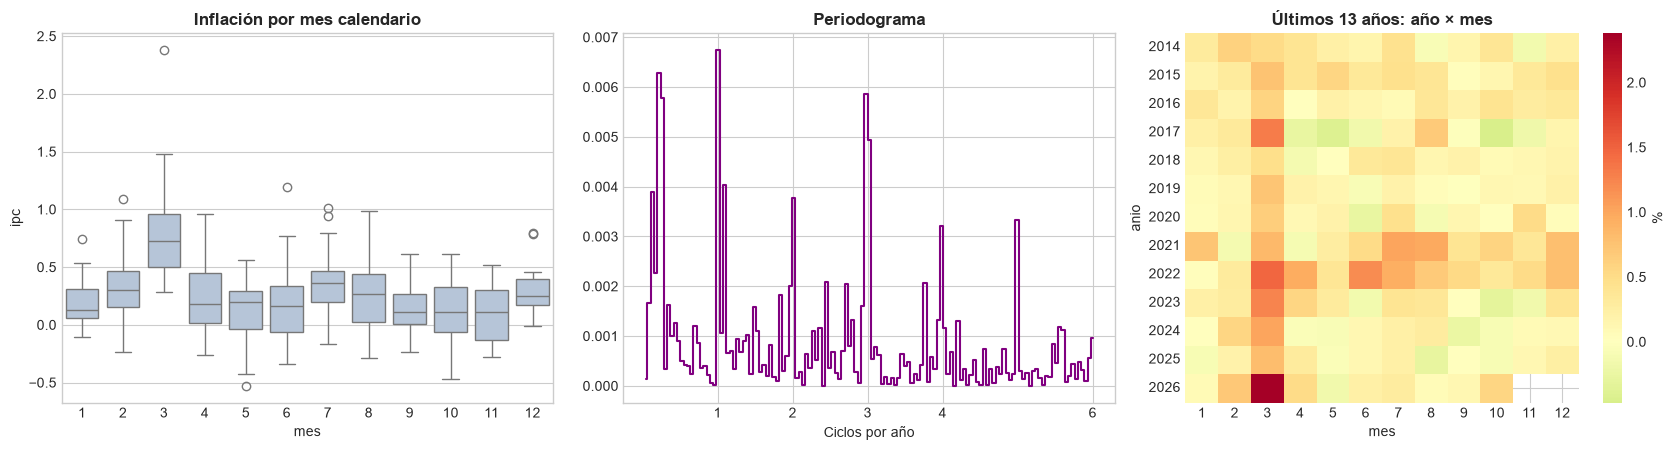

Meses con mayor inflación promedio: 3 (0.82%), 7 (0.37%), 2 (0.32%)
Meses con menor inflación promedio: 11 (0.11%), 5 (0.12%), 10 (0.13%)


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
tmp = df_base[["ipc"]].copy(); tmp["mes"] = tmp.index.month
sns.boxplot(data=tmp, x="mes", y="ipc", color="lightsteelblue", ax=ax[0]); ax[0].set_title("Inflación por mes calendario")
f, esp = periodogram(df_base["ipc"], fs=12, detrend="linear", scaling="spectrum")
ax[1].step(f[1:], esp[1:], where="mid", color="purple")
ax[1].set_xticks([1, 2, 3, 4, 6]); ax[1].set_xlabel("Ciclos por año"); ax[1].set_title("Periodograma")
pivote = tmp.assign(anio=tmp.index.year).pivot(index="anio", columns="mes", values="ipc")
sns.heatmap(pivote.loc[pivote.index >= pivote.index.max() - 12], cmap="RdYlGn_r", center=0, ax=ax[2], cbar_kws={"label": "%"})
ax[2].set_title("Últimos 13 años: año × mes")
plt.tight_layout(); plt.show()
est = tmp.groupby("mes")["ipc"].mean()
print("Meses con mayor inflación promedio:", ", ".join(f"{m} ({v:.2f}%)" for m, v in est.nlargest(3).items()))
print("Meses con menor inflación promedio:", ", ".join(f"{m} ({v:.2f}%)" for m, v in est.nsmallest(3).items()))

### 5.5 Correlaciones

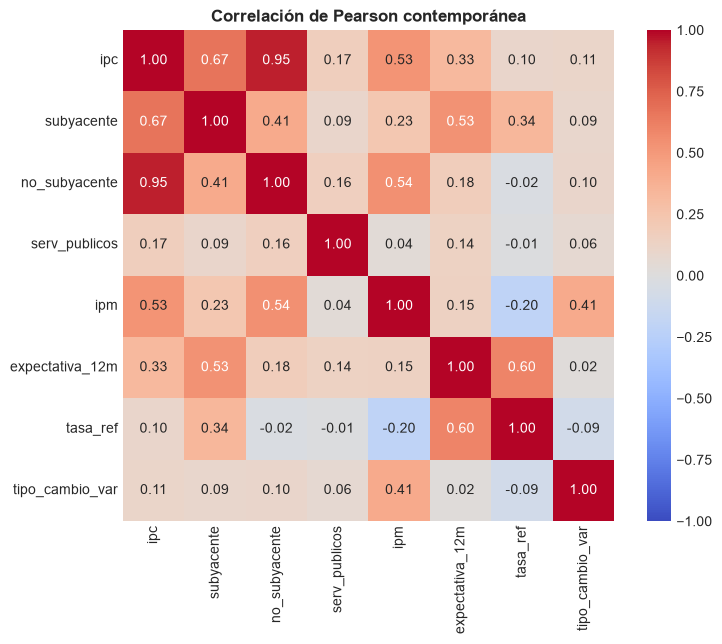

,"corr(x_t, IPC_{t+1})"
ipm,0.2877
ipc,0.2383
no_subyacente,0.1902
subyacente,0.1882
expectativa_12m,0.1765
tipo_cambio_var,0.1763
serv_publicos,0.0430
tasa_ref,0.0399


In [ ]:
cols_corr = ["ipc", "subyacente", "no_subyacente", "serv_publicos", "ipm", "expectativa_12m", "tasa_ref", "tipo_cambio_var"]
plt.figure(figsize=(8, 6.5))
sns.heatmap(df_base[cols_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Pearson contemporánea"); plt.tight_layout(); plt.show()

# Correlación de cada variable (en t) con la inflación del mes siguiente, SOLO tramo de entrenamiento
tr = df_base.loc[:fecha_corte_val]
corr_sig = {c: tr[c].corr(tr["ipc"].shift(-1)) for c in cols_corr}
corr_sig = pd.Series(corr_sig).sort_values(ascending=False)
display(corr_sig.rename("corr(x_t, IPC_{t+1})").to_frame())

### 5.6 Autocorrelación

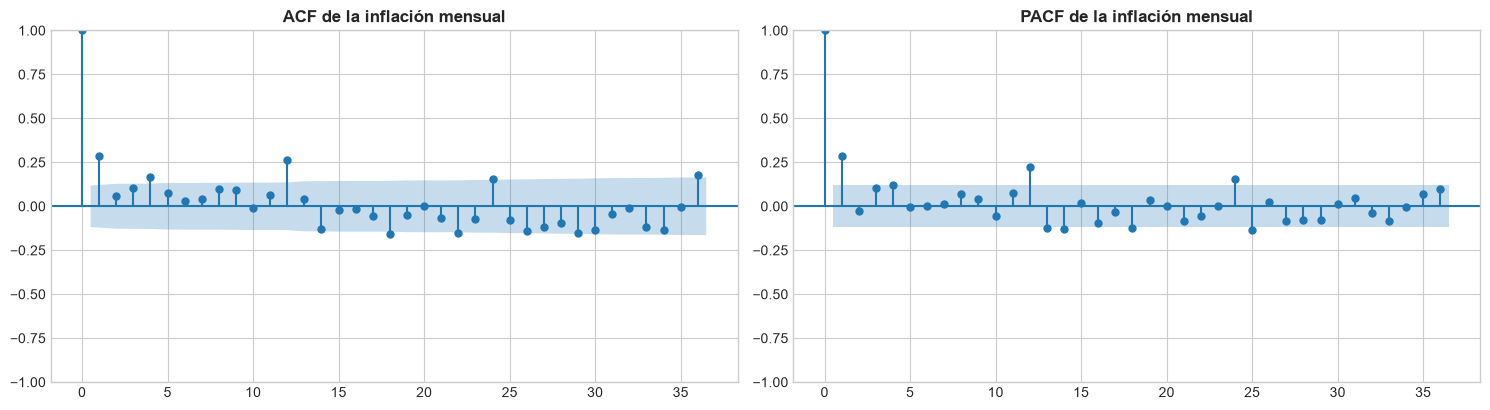

Rezagos con PACF significativo (|φ| > 0.118): [1, 4, 12, 13, 14, 18, 24]


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
plot_acf(df_base["ipc"], lags=36, ax=ax[0]); ax[0].set_title("ACF de la inflación mensual")
plot_pacf(df_base["ipc"], lags=36, method="ywm", ax=ax[1]); ax[1].set_title("PACF de la inflación mensual")
plt.tight_layout(); plt.show()
lim = 1.96 / np.sqrt(len(df_base))

pac = _pacf(df_base["ipc"], nlags=24, method="ywm")
sig = [k for k in range(1, 25) if abs(pac[k]) > lim]
print(f"Rezagos con PACF significativo (|φ| > {lim:.3f}): {sig}")

### 5.7 Hallazgos principales (generados a partir de los resultados)

In [ ]:
c_ipm   = corr_sig.get("ipm", np.nan); c_exp = corr_sig.get("expectativa_12m", np.nan)
c_ipc   = corr_sig.get("ipc", np.nan)
print("HALLAZGOS DEL EDA")
linea()
print(f"1. Memoria: la correlación entre IPC_t e IPC_(t+1) en entrenamiento es {c_ipc:.2f}; "
      f"PACF significativo en los rezagos {sig[:6]}.")
print(f"2. Indicadores: corr(IPM_t, IPC_(t+1)) = {c_ipm:.2f}; corr(Expectativa_t, IPC_(t+1)) = {c_exp:.2f}.")
print(f"3. Distribución: asimetría {d.skew():.2f}, curtosis exceso {d.kurt():.2f} "
      f"({'colas pesadas' if d.kurt() > 1 else 'colas moderadas'}).")
print(f"4. Estacionalidad: picos de inflación media en los meses {list(est.nlargest(2).index)}.")
print(f"5. Volatilidad: la desviación estándar móvil de 12 m va de {df_base['ipc'].rolling(12).std().min():.2f} a "
      f"{df_base['ipc'].rolling(12).std().max():.2f} (heterocedasticidad entre regímenes).")

HALLAZGOS DEL EDA
--------------------------------------------------------------------------------
1. Memoria: la correlación entre IPC_t e IPC_(t+1) en entrenamiento es 0.24; PACF significativo en los rezagos [1, 4, 12, 13, 14, 18].
2. Indicadores: corr(IPM_t, IPC_(t+1)) = 0.29; corr(Expectativa_t, IPC_(t+1)) = 0.18.
3. Distribución: asimetría 1.34, curtosis exceso 5.19 (colas pesadas).
4. Estacionalidad: picos de inflación media en los meses [3, 7].
5. Volatilidad: la desviación estándar móvil de 12 m va de 0.16 a 0.70 (heterocedasticidad entre regímenes).


### 5.8 Validación de supuestos y condiciones de modelamiento (Etapa 4)

Cada comprobación se registra en la tabla `SUPUESTOS` (supuesto → prueba → resultado → ¿cumple? → implicación). Las comprobaciones de *fuga de información* y *generalización* se completan en las secciones 7.3 y 12.5, porque requieren las variables construidas y los resultados de los modelos.

--------------------------------------------------------------------------------
1. CONSISTENCIA TEMPORAL
Meses faltantes: 0 · duplicados: 0 · NaN en IPC: 0
--------------------------------------------------------------------------------
2. DISPONIBILIDAD DE INDICADORES


,día publicación,rezago aplicado (meses)
ipc,1,0
subyacente,1,0
no_subyacente,1,0
serv_publicos,1,0
ipm,15,1
expectativa_12m,15,1
tasa_ref,1,0
tipo_cambio,1,0
tipo_cambio_var,1,0


--------------------------------------------------------------------------------
3. ESTABILIDAD DE LA SERIE
Media 1ª mitad=0.249 · 2ª mitad=0.282  (Welch p=0.441)
Desv. 1ª mitad=0.290 · 2ª mitad=0.393  (Levene p=0.149)
CUSUM de residuos: estadístico=1.283, p=0.074
--------------------------------------------------------------------------------
4. ESTACIONARIEDAD (ADF: H0 raíz unitaria · KPSS: H0 estacionaria)


,ADF stat,p ADF,p KPSS,diagnóstico
variable,,,,
ipc,-3.5196,0.0075,0.1000,Estacionaria
subyacente,-4.8227,0.0000,0.1000,Estacionaria
no_subyacente,-11.6478,0.0000,0.1000,Estacionaria
ipm,-9.3539,0.0000,0.1000,Estacionaria
expectativa_12m,-4.1159,0.0009,0.1000,Estacionaria
tasa_ref,-3.6108,0.0056,0.1000,Estacionaria
tipo_cambio_var,-7.4797,0.0000,0.1000,Estacionaria


--------------------------------------------------------------------------------
5. ESTACIONALIDAD (STL)


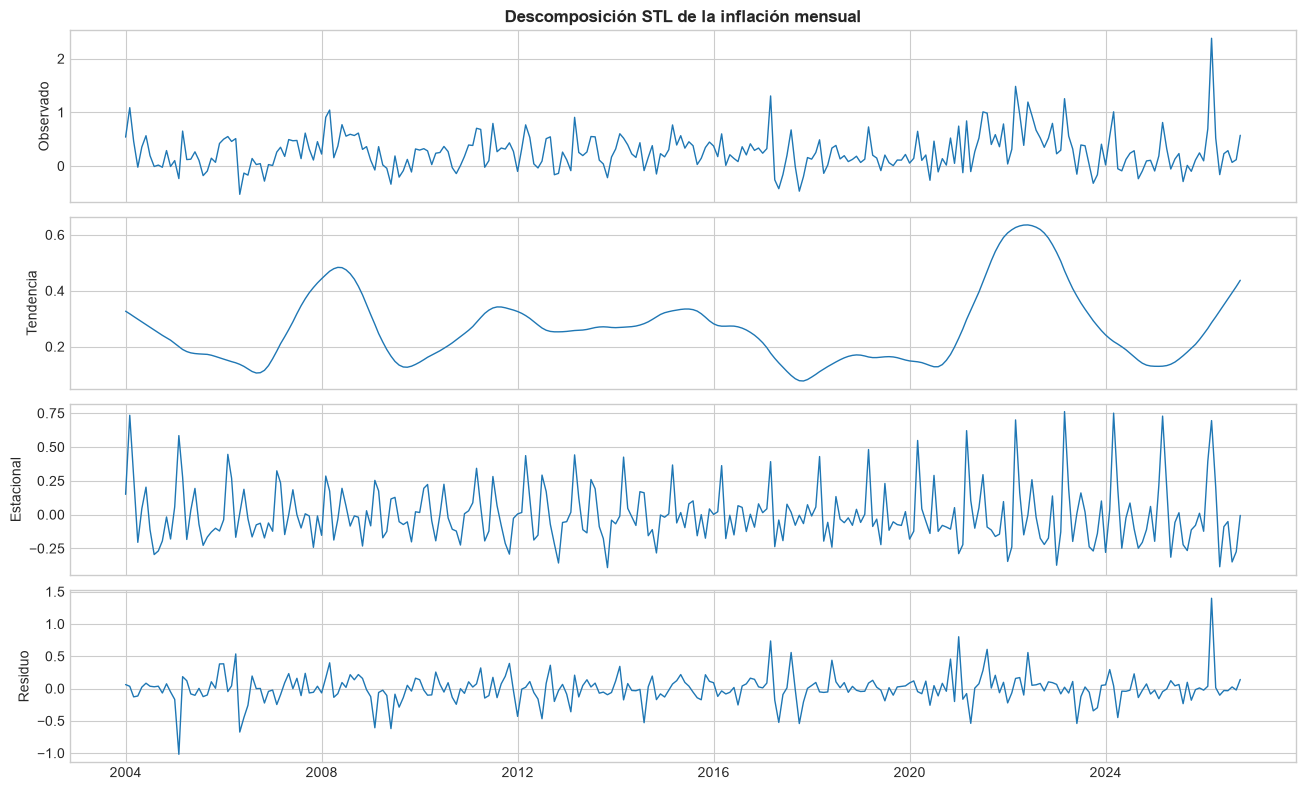

Fuerza de la estacionalidad (Hyndman): 0.48  (0 = nula, 1 = total)


In [ ]:
SUPUESTOS = []
def registrar(supuesto, prueba, resultado, cumple, implicacion):
    SUPUESTOS.append({"Supuesto": supuesto, "Prueba": prueba, "Resultado": resultado,
                      "¿Cumple?": cumple, "Implicación": implicacion})

# --- 1. Consistencia temporal ---------------------------------------------------------------
linea(); print("1. CONSISTENCIA TEMPORAL")
rango = pd.date_range(df_base.index.min(), df_base.index.max(), freq="MS")
faltan = len(rango.difference(df_base.index)); dup = int(df_base.index.duplicated().sum())
nan_ipc = int(df_base["ipc"].isna().sum())
print(f"Meses faltantes: {faltan} · duplicados: {dup} · NaN en IPC: {nan_ipc}")
registrar("Consistencia temporal", "Continuidad, duplicados y NaN del IPC",
          f"{faltan} faltantes, {dup} duplicados, {nan_ipc} NaN", "Sí" if faltan == dup == nan_ipc == 0 else "No",
          "Serie mensual continua; no se requiere imputación del objetivo")

# --- 2. Disponibilidad de indicadores ---------------------------------------------------------
linea(); print("2. DISPONIBILIDAD DE INDICADORES")
disp = pd.DataFrame({"día publicación": DIA_PUB, "rezago aplicado (meses)": LAG_DISP})
display(disp)
tarde = [k for k, v in LAG_DISP.items() if v == 1]
registrar("Disponibilidad de indicadores", f"Comparación día de publicación vs. día de emisión ({DIA_EMISION})",
          f"Rezago de 1 mes en: {', '.join(tarde) or 'ninguna'}", "Sí (por construcción)",
          "Cada variable se desplaza según su fecha de publicación; verificar calendarios oficiales (supuesto)")

# --- 3. Estabilidad: cambios de media/varianza -------------------------------------------------
linea(); print("3. ESTABILIDAD DE LA SERIE")
mitad = len(df_base) // 2
a, b = df_base["ipc"].iloc[:mitad], df_base["ipc"].iloc[mitad:]
lev = stats.levene(a, b); tt = stats.ttest_ind(a, b, equal_var=False)
print(f"Media 1ª mitad={a.mean():.3f} · 2ª mitad={b.mean():.3f}  (Welch p={tt.pvalue:.3f})")
print(f"Desv. 1ª mitad={a.std():.3f} · 2ª mitad={b.std():.3f}  (Levene p={lev.pvalue:.3f})")
try:
    cus = breaks_cusumolsresid((df_base["ipc"] - df_base["ipc"].mean()).to_numpy(), ddof=1)
    p_cusum = cus[1]; print(f"CUSUM de residuos: estadístico={cus[0]:.3f}, p={p_cusum:.3f}")
except Exception as e:
    p_cusum = np.nan; print("CUSUM no disponible:", e)
estable = (tt.pvalue > .05) and (lev.pvalue > .05) and (np.isnan(p_cusum) or p_cusum > .05)
registrar("Estabilidad (media / varianza / cambios estructurales)", "Welch, Levene y CUSUM",
          f"p(media)={tt.pvalue:.3f}; p(varianza)={lev.pvalue:.3f}; p(CUSUM)={p_cusum:.3f}",
          "Sí" if estable else "Parcial",
          "Régimen estable" if estable else "Hay cambios de régimen → validar con ventana expansiva y reportar error por subperiodo")

# --- 4. Estacionariedad (ADF + KPSS) para el IPC y los indicadores ----------------------------
linea(); print("4. ESTACIONARIEDAD (ADF: H0 raíz unitaria · KPSS: H0 estacionaria)")
filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for c in ["ipc", "subyacente", "no_subyacente", "ipm", "expectativa_12m", "tasa_ref", "tipo_cambio_var"]:
        s = df_base[c].dropna()
        p_adf = adfuller(s, autolag="AIC")[1]
        p_kpss = kpss(s, regression="c", nlags="auto")[1]
        if p_adf < .05 and p_kpss >= .05: dx = "Estacionaria"
        elif p_adf >= .05 and p_kpss < .05: dx = "No estacionaria"
        else: dx = "Evidencia mixta"
        filas.append({"variable": c, "ADF stat": adfuller(s, autolag="AIC")[0], "p ADF": p_adf, "p KPSS": p_kpss, "diagnóstico": dx})
tabla_est = pd.DataFrame(filas).set_index("variable")
display(tabla_est)
dx_ipc = tabla_est.loc["ipc", "diagnóstico"]
no_est = tabla_est.index[tabla_est["diagnóstico"] == "No estacionaria"].tolist()
registrar("Estacionariedad", "ADF + KPSS (IPC y predictores)",
          f"IPC: {dx_ipc}; no estacionarias: {no_est or 'ninguna'}", "Sí" if dx_ipc == "Estacionaria" and not no_est else "Parcial",
          "La tasa de referencia (nivel) suele ser persistente → se incorpora también en diferencias" if "tasa_ref" in no_est
          else "Los modelos pueden trabajar con la serie en niveles de variación mensual")

# --- 5. Estacionalidad (STL) --------------------------------------------------------------------
linea(); print("5. ESTACIONALIDAD (STL)")
stl = STL(df_base["ipc"], period=12, robust=True).fit()
fuerza_est = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
fig, ax = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for a_, s_, t_ in zip(ax, [stl.observed, stl.trend, stl.seasonal, stl.resid], ["Observado", "Tendencia", "Estacional", "Residuo"]):
    a_.plot(s_, lw=1); a_.set_ylabel(t_)
ax[0].set_title("Descomposición STL de la inflación mensual"); plt.tight_layout(); plt.show()
print(f"Fuerza de la estacionalidad (Hyndman): {fuerza_est:.2f}  (0 = nula, 1 = total)")
registrar("Estacionalidad", "STL (periodo 12) – fuerza estacional",
          f"Fuerza = {fuerza_est:.2f}", "Sí" if fuerza_est > .25 else "Débil",
          "Se incluyen mes (seno/coseno) y rezago anual" if fuerza_est > .25 else "Estacionalidad débil: se mantiene el rezago anual y mes como variables de control")

---
# FASE 3 — Preparación de los Datos
## 6. Integración y Depuración (Etapa 2)

### 6.1-6.4 Unificación temporal, faltantes y duplicados
Todas las series ya comparten el índice mensual (`MS` = primer día de cada mes) construido en la sección 3. Se confirma que el índice es único, creciente y continuo, y que no quedan faltantes.

In [ ]:
df_maestro = df_base.copy()
assert df_maestro.index.is_monotonic_increasing and df_maestro.index.is_unique
assert df_maestro.index.equals(pd.date_range(df_maestro.index[0], df_maestro.index[-1], freq="MS"))
assert df_maestro["ipc"].notna().all()
linea(); print("DATASET MAESTRO")
print(f"{df_maestro.shape[0]} meses × {df_maestro.shape[1]} variables · {df_maestro.index.min():%Y-%m} → {df_maestro.index.max():%Y-%m}")
display(df_maestro.tail())

--------------------------------------------------------------------------------
DATASET MAESTRO
274 meses × 9 variables · 2004-01 → 2026-10


,ipc,subyacente,no_subyacente,serv_publicos,ipm,expectativa_12m,tasa_ref,tipo_cambio,tipo_cambio_var
fecha,,,,,,,,,
2026-06-01,0.2288,0.1760,0.3375,0.0504,-0.9569,2.8250,4.2500,3.4060,-0.8533
2026-07-01,0.2856,0.2397,0.3793,-0.1029,0.5480,3.0088,4.2500,3.4002,-0.1684
2026-08-01,0.0668,0.1172,-0.0353,1.1854,1.2204,3.0500,4.2500,3.3630,-1.0963
2026-09-01,0.1173,0.1383,0.0741,0.1282,0.5739,3.0875,4.2500,3.3791,0.4804
2026-10-01,0.5715,0.2587,1.2105,-0.6815,0.7384,3.0542,4.2500,3.4421,1.8629


### 6.5 Matriz de recolección de datos (instrumento – Anexo 14 de la tesis)
Estructura exigida: *Variable · Código · Periodo · Valor · Unidad · Fuente · Fecha de disponibilidad · Transformación*.

In [ ]:
TRANSFORMACION = {k: ("Ninguna (variación % mensual publicada)" if v["freq"] == "M" else
                      ("Último dato del mes" if v["agg"] == "last" else "Promedio mensual de datos diarios"))
                  for k, v in CATALOGO.items()}
TRANSFORMACION["tipo_cambio_var"] = DERIVADAS["tipo_cambio_var"]["transf"]
META = {k: (v["codigo"], v["unidad"], v["fuente"]) for k, v in CATALOGO.items()}
META["tipo_cambio_var"] = ("derivada", DERIVADAS["tipo_cambio_var"]["unidad"], "Elaboración propia")

filas = []
for var in df_maestro.columns:
    cod, uni, fte = META[var]
    s = df_maestro[var].dropna()
    disponible = (s.index + pd.offsets.MonthBegin(1) + pd.Timedelta(days=DIA_PUB[var] - 1))
    filas.append(pd.DataFrame({"Variable": var, "Código": cod, "Periodo": s.index.strftime("%Y-%m"), "Valor": s.values,
                               "Unidad": uni, "Fuente": fte, "Fecha de disponibilidad (estimada)": disponible.strftime("%Y-%m-%d"),
                               "Transformación": TRANSFORMACION[var]}))
matriz_recoleccion = pd.concat(filas, ignore_index=True)
matriz_recoleccion.to_csv(OUT / "matriz_recoleccion_datos.csv", index=False, encoding="utf-8-sig")
print(f"Matriz de recolección: {len(matriz_recoleccion):,} registros → {OUT/'matriz_recoleccion_datos.csv'}")
display(matriz_recoleccion.sample(6, random_state=SEED).sort_index())

Matriz de recolección: 2,466 registros → salidas_alerta_inflacion\matriz_recoleccion_datos.csv


,Variable,Código,Periodo,Valor,Unidad,Fuente,Fecha de disponibilidad (estimada),Transformación
84,ipc,PN01364PM,2011-01,0.3904,% var. mensual,BCRP / INEI,2011-02-01,Ninguna (variación % mensual publicada)
269,ipc,PN01364PM,2026-06,0.2288,% var. mensual,BCRP / INEI,2026-07-01,Ninguna (variación % mensual publicada)
601,no_subyacente,PN01307PM,2008-06,1.0650,% var. mensual,BCRP / INEI,2008-07-01,Ninguna (variación % mensual publicada)
912,serv_publicos,PN01311PM,2011-07,0.4428,% var. mensual,BCRP / INEI,2011-08-01,Ninguna (variación % mensual publicada)
1194,ipm,PN01286PM,2012-03,0.6078,% var. mensual,BCRP / INEI,2012-04-15,Ninguna (variación % mensual publicada)
1234,ipm,PN01286PM,2015-07,-0.0429,% var. mensual,BCRP / INEI,2015-08-15,Ninguna (variación % mensual publicada)


---
## 7. Ingeniería de Variables (Etapa 5)

**Regla central:** cada variable se *desplaza primero según su disponibilidad* (`LAG_DISP`) y **después** se generan rezagos, promedios y diferencias. Así, ninguna columna de la fila del origen $t$ contiene información posterior a $t$.

Familias de variables (sección 8.6-8.7 de la tesis):

| Familia | Variables |
|---|---|
| Inflación | IPC en $t, t-1, t-2, t-3, t-6, t-12$ · medias móviles 3/6/12 · desviación móvil 3/12 · diferencia de 1 mes |
| Componentes | subyacente, no subyacente, servicios públicos, IPM: valor, rezagos 1 y 3, media móvil 3 |
| Expectativas | nivel, rezagos 1 y 3, diferencia de 1 mes |
| Política monetaria | nivel de la tasa de referencia, cambio a 1 y 6 meses |
| Sector externo | variación % del tipo de cambio, rezagos 1 y 3, media móvil 3 |
| Calendario (mes objetivo) | seno y coseno del mes, trimestre, tendencia |

In [ ]:
def construir_features(df):
    """Matriz de características en el ORIGEN t. Solo usa información publicada hasta t."""
    disp = pd.DataFrame({c: df[c].shift(LAG_DISP[c]) for c in df.columns})   # información disponible
    X = pd.DataFrame(index=df.index)

    # 1) Historial de la inflación
    for k in (0, 1, 2, 3, 6, 12):
        X[f"ipc_l{k}"] = disp["ipc"].shift(k)
    for w in (3, 6, 12):
        X[f"ipc_ma{w}"] = disp["ipc"].rolling(w).mean()
    X["ipc_std3"]  = disp["ipc"].rolling(3).std()
    X["ipc_std12"] = disp["ipc"].rolling(12).std()
    X["ipc_dif1"]  = disp["ipc"].diff()

    # 2) Componentes e indicadores de precios
    for c in ("subyacente", "no_subyacente", "serv_publicos", "ipm"):
        X[f"{c}_l0"] = disp[c]
        X[f"{c}_l1"] = disp[c].shift(1)
        X[f"{c}_l3"] = disp[c].shift(3)
        X[f"{c}_ma3"] = disp[c].rolling(3).mean()

    # 3) Expectativas
    X["expec_l0"]   = disp["expectativa_12m"]
    X["expec_l1"]   = disp["expectativa_12m"].shift(1)
    X["expec_l3"]   = disp["expectativa_12m"].shift(3)
    X["expec_dif1"] = disp["expectativa_12m"].diff()

    # 4) Política monetaria
    X["tasa_ref"]      = disp["tasa_ref"]
    X["tasa_ref_dif1"] = disp["tasa_ref"].diff()
    X["tasa_ref_dif6"] = disp["tasa_ref"].diff(6)

    # 5) Sector externo
    X["tc_var_l0"]  = disp["tipo_cambio_var"]
    X["tc_var_l1"]  = disp["tipo_cambio_var"].shift(1)
    X["tc_var_l3"]  = disp["tipo_cambio_var"].shift(3)
    X["tc_var_ma3"] = disp["tipo_cambio_var"].rolling(3).mean()

    # 6) Calendario del MES OBJETIVO (t+1) y tendencia
    mes_obj = (df.index.month % 12) + 1
    X["mes_sin"] = np.sin(2 * np.pi * mes_obj / 12)
    X["mes_cos"] = np.cos(2 * np.pi * mes_obj / 12)
    X["trimestre_obj"] = (mes_obj - 1) // 3 + 1
    X["tendencia"] = (df.index.year - 2000) * 12 + df.index.month
    return X

X_all = construir_features(df_base)
print(f"Variables construidas: {X_all.shape[1]}")
print(", ".join(X_all.columns))

Variables construidas: 43
ipc_l0, ipc_l1, ipc_l2, ipc_l3, ipc_l6, ipc_l12, ipc_ma3, ipc_ma6, ipc_ma12, ipc_std3, ipc_std12, ipc_dif1, subyacente_l0, subyacente_l1, subyacente_l3, subyacente_ma3, no_subyacente_l0, no_subyacente_l1, no_subyacente_l3, no_subyacente_ma3, serv_publicos_l0, serv_publicos_l1, serv_publicos_l3, serv_publicos_ma3, ipm_l0, ipm_l1, ipm_l3, ipm_ma3, expec_l0, expec_l1, expec_l3, expec_dif1, tasa_ref, tasa_ref_dif1, tasa_ref_dif6, tc_var_l0, tc_var_l1, tc_var_l3, tc_var_ma3, mes_sin, mes_cos, trimestre_obj, tendencia


### 7.1-7.2 Construcción del objetivo y dataset supervisado (Etapa 6)
Cada fila es un **origen** $t$; el objetivo es $\pi_{t+1}$ (`ipc.shift(-1)`). La última fila (sin objetivo todavía) se reserva para el **pronóstico operativo**.

In [ ]:
y_all = df_base["ipc"].shift(-1).rename("target_ipc_t1")

X_valido = X_all.dropna()
idx_sup  = X_valido.index.intersection(y_all.dropna().index)
X_m = X_valido.loc[idx_sup].copy()
y_m = y_all.loc[idx_sup].copy()
X_live = X_valido.iloc[[-1]].copy()               # origen operativo: objetivo aún desconocido

assert X_m.index.equals(y_m.index) and X_m.index.is_monotonic_increasing
assert X_m.index.equals(pd.date_range(X_m.index[0], X_m.index[-1], freq="MS")), "El dataset supervisado debe ser mensual continuo"
assert X_live.index[0] == df_base.index[-1] and X_live.index[0] > X_m.index[-1]
assert not X_live.isna().any().any(), "El origen operativo tiene variables sin dato; revise la publicación de las series"

fecha_origen_live = X_live.index[0]
fecha_objetivo_live = fecha_origen_live + pd.offsets.MonthBegin(1)
print(f"Observaciones supervisadas: {len(X_m)} ({X_m.index[0]:%Y-%m} → {X_m.index[-1]:%Y-%m}) · variables: {X_m.shape[1]}")
print(f"Origen operativo: {fecha_origen_live:%Y-%m}  →  mes a pronosticar: {fecha_objetivo_live:%Y-%m}")
display(X_m.tail(3).T.head(12))

Observaciones supervisadas: 261 (2005-01 → 2026-09) · variables: 43
Origen operativo: 2026-10  →  mes a pronosticar: 2026-11


fecha,2026-07-01,2026-08-01,2026-09-01
ipc_l0,0.2856,0.0668,0.1173
ipc_l1,0.2288,0.2856,0.0668
ipc_l2,-0.1613,0.2288,0.2856
ipc_l3,0.5206,-0.1613,0.2288
ipc_l6,0.0958,0.6936,2.3787
ipc_l12,0.2314,-0.2903,0.0112
ipc_ma3,0.1177,0.1937,0.1566
ipc_ma6,0.6577,0.5532,0.1763
ipc_ma12,0.3348,0.3646,0.3734
ipc_std3,0.2433,0.1135,0.1146


### 7.3 Pruebas anti-fuga de información (Etapa 4 · supuesto "prevención de fuga")
Dos pruebas automáticas sobre la construcción de variables:

1. **Truncamiento:** para varios orígenes $t$ se recalculan las variables usando solo datos hasta $t$; deben coincidir exactamente con las de la matriz completa (si no, una variable usaría el futuro).
2. **Enmascarado de lo no publicado:** además se borra en el dato truncado el último valor de las variables con rezago 1 (aún no publicadas en $t$); las variables resultantes deben seguir siendo idénticas (prueba de que no se usa información no disponible).

In [ ]:
def prueba_truncamiento(n_origenes=12, enmascarar=True):
    rng = np.random.default_rng(SEED)
    posiciones = rng.choice(np.arange(24, len(X_m) - 1), size=n_origenes, replace=False)
    fallos = []
    for p in posiciones:
        t = X_m.index[p]
        d = df_base.loc[:t].copy()
        if enmascarar:
            for c, lag in LAG_DISP.items():
                if lag >= 1 and c in d.columns:
                    d.loc[t, c] = np.nan                      # dato del mes t aún no publicado en el origen
        Xt = construir_features(d).loc[t]
        ref = X_m.loc[t]
        if not np.allclose(Xt.to_numpy(float), ref.to_numpy(float), equal_nan=True):
            fallos.append((t, list(ref.index[~np.isclose(Xt.to_numpy(float), ref.to_numpy(float), equal_nan=True)])))
    return posiciones, fallos

_, fallos_a = prueba_truncamiento(enmascarar=False)
_, fallos_b = prueba_truncamiento(enmascarar=True)
print("Prueba 1 (truncamiento):", "APROBADA" if not fallos_a else f"FALLA {fallos_a[:2]}")
print("Prueba 2 (enmascarado de datos no publicados):", "APROBADA" if not fallos_b else f"FALLA {fallos_b[:2]}")
assert not fallos_a and not fallos_b, "Hay fuga de información en la construcción de variables"
registrar("Prevención de fuga (variables)", "Truncamiento y enmascarado en 12 orígenes aleatorios",
          "Variables idénticas con datos truncados", "Sí", "Las características no usan información posterior al origen")

Prueba 1 (truncamiento): APROBADA
Prueba 2 (enmascarado de datos no publicados): APROBADA


---
## 8. División Temporal del Dataset (Etapa 8)

Partición **cronológica estricta**: entrenamiento inicial → validación (selección de modelo) → prueba final (se usa una sola vez).
Dentro de validación y prueba el modelo se re-entrena cada mes con **ventana expansiva** (sección 11).

PARTICIÓN CRONOLÓGICA (por fecha de ORIGEN)
Entrenamiento inicial: 201 | 2005-01 → 2021-09
Validación           :  36 | 2021-10 → 2024-09
Prueba               :  24 | 2024-10 → 2026-09


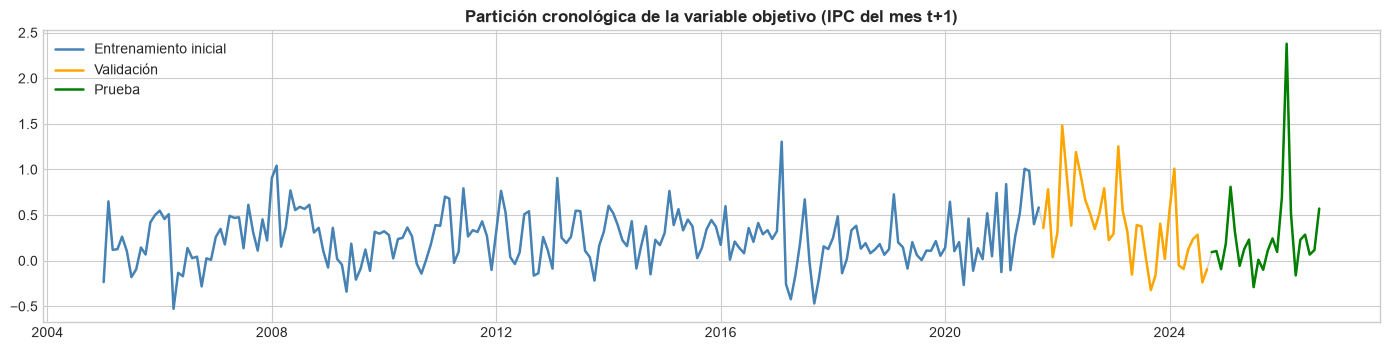

In [ ]:
N = len(X_m)
pos_ini_val  = N - N_VAL - N_TEST
pos_ini_test = N - N_TEST
assert pos_ini_val >= MIN_TRAIN, f"Se necesitan al menos {MIN_TRAIN} meses de entrenamiento inicial (hay {pos_ini_val})"

idx_train0 = X_m.index[:pos_ini_val]
idx_val    = X_m.index[pos_ini_val:pos_ini_test]
idx_test   = X_m.index[pos_ini_test:]
ORIGENES   = list(range(pos_ini_val, N))

print("PARTICIÓN CRONOLÓGICA (por fecha de ORIGEN)")
print(f"Entrenamiento inicial: {len(idx_train0):3d} | {idx_train0[0]:%Y-%m} → {idx_train0[-1]:%Y-%m}")
print(f"Validación           : {len(idx_val):3d} | {idx_val[0]:%Y-%m} → {idx_val[-1]:%Y-%m}")
print(f"Prueba               : {len(idx_test):3d} | {idx_test[0]:%Y-%m} → {idx_test[-1]:%Y-%m}")

fig, ax = plt.subplots(figsize=(14, 3.6))
ax.plot(y_m.index, y_m.values, color="lightgray", lw=1)
for idx, col, lab in [(idx_train0, "steelblue", "Entrenamiento inicial"), (idx_val, "orange", "Validación"), (idx_test, "green", "Prueba")]:
    ax.plot(idx, y_m.loc[idx], color=col, lw=1.8, label=lab)
ax.set_title("Partición cronológica de la variable objetivo (IPC del mes t+1)"); ax.legend(); plt.tight_layout(); plt.show()

---
# FASE 4 — Modelado (Etapa 7)

## 9. Modelos de referencia (líneas base)

| Modelo | Regla |
|---|---|
| **Persistencia** (obligatoria en la tesis) | $\hat\pi_{t+1}=\pi_t$ |
| Naive estacional | $\hat\pi_{t+1}=\pi_{t-11}$ (mismo mes del año anterior) |
| Media histórica | promedio de $\pi$ hasta el origen (ventana expansiva) |

Todas usan únicamente información disponible en el origen.

In [ ]:
ipc = df_base["ipc"]
fechas_orig = X_m.index[ORIGENES]

BASES = {
    "Persistencia":      X_m["ipc_l0"],                                        # π_t
    "Naive estacional":  ipc.shift(11).reindex(X_m.index),                    # π_{t-11}
    "Media histórica":   y_m.expanding().mean().shift(1),                     # media de objetivos ya conocidos
}
pred_bases = {k: v.loc[fechas_orig] for k, v in BASES.items()}

def metricas(real, pred):
    d = pd.concat([real.rename("r"), pred.rename("p")], axis=1).dropna()
    if d.empty:
        return {"N": 0, "MAE": np.nan, "RMSE": np.nan}
    return {"N": len(d), "MAE": mean_absolute_error(d.r, d.p), "RMSE": float(np.sqrt(mean_squared_error(d.r, d.p)))}

print("Líneas base listas:", list(pred_bases))

Líneas base listas: ['Persistencia', 'Naive estacional', 'Media histórica']


## 10. Modelos predictivos

### 10.1 Modelos de aprendizaje automático (propuestos en la tesis)
* **Ridge** y **Lasso** (secciones 8.10): el parámetro de regularización se elige **dentro de cada ventana de entrenamiento** con `TimeSeriesSplit` (sin mirar el futuro); el *scaler* está dentro del `Pipeline`, de modo que se ajusta solo con datos de entrenamiento.
* **Random Forest** (8.11) y **XGBoost** (8.12): hiperparámetros conservadores fijados *a priori* (la muestra mensual es pequeña; no se afinan sobre validación para evitar sobreajuste).
* **Ensamble** (promedio de los cuatro): Flores y Grandez (2024) reportan mejoras al combinar pronósticos.

### 10.2 Modelos de series de tiempo (referencia metodológica, 8.13)
ARIMA(1,0,1) y SARIMA(1,0,1)(1,0,0)$_{12}$ univariados, con la historia del IPC hasta el origen.

In [ ]:
MODELOS_ML = {
    "Ridge": Pipeline([("scaler", StandardScaler()),
                       ("modelo", RidgeCV(alphas=np.logspace(-2, 3, 30), cv=TimeSeriesSplit(5)))]),
    "Lasso": Pipeline([("scaler", StandardScaler()),
                       ("modelo", LassoCV(alphas=np.logspace(-3, 0.5, 40), cv=TimeSeriesSplit(5), max_iter=50_000))]),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=5,
                                           max_features=0.5, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=2, subsample=0.8,
                            colsample_bytree=0.8, min_child_weight=3, reg_lambda=5.0,
                            random_state=SEED, n_jobs=1, verbosity=0),
}
MODELOS_TS = {
    "ARIMA(1,0,1)":  dict(order=(1, 0, 1), seasonal_order=(0, 0, 0, 0)),
    "SARIMA":        dict(order=(1, 0, 1), seasonal_order=(1, 0, 0, 12)),
}
print("ML :", list(MODELOS_ML)); print("TS :", list(MODELOS_TS))

ML : ['Ridge', 'Lasso', 'Random Forest', 'XGBoost']
TS : ['ARIMA(1,0,1)', 'SARIMA']


## 11. Validación temporal — ventana expansiva (Etapa 8)

Para cada origen $i$ de validación y prueba:

1. **Entrenar** con las filas $0,\dots,i-1$ (sus objetivos $\pi_1,\dots,\pi_i$ ya están publicados en el origen $i$).
2. **Predecir** $\hat\pi_{i+1}$ con las variables de la fila $i$.
3. Incorporar la observación y repetir.

La función verifica con un `assert` que **el último objetivo usado para entrenar es anterior o igual a la fecha del origen**.

In [ ]:
def _asegurar_sin_fuga(i):
    ultimo_objetivo_train = y_m.index[i - 1] + pd.offsets.MonthBegin(1)    # fecha del mes que es objetivo de la fila i-1
    assert ultimo_objetivo_train <= X_m.index[i], "FUGA: se entrena con un objetivo posterior al origen"

def predecir_en_origen(nombre, i):
    """Pronostica π_{t+1} en el origen i usando solo información hasta i."""
    _asegurar_sin_fuga(i)
    if nombre in MODELOS_ML:
        m = clone(MODELOS_ML[nombre])
        m.fit(X_m.iloc[:i], y_m.iloc[:i])
        return float(m.predict(X_m.iloc[[i]])[0])
    if nombre in MODELOS_TS:
        esp = MODELOS_TS[nombre]
        endog = ipc.loc[:X_m.index[i]].to_numpy()                          # IPC conocido hasta el origen (incluido)
        res = SARIMAX(endog, order=esp["order"], seasonal_order=esp["seasonal_order"], trend="c",
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        return float(np.asarray(res.forecast(1))[0])
    raise KeyError(nombre)

def walk_forward(nombre, origenes=ORIGENES):
    pred, errores = {}, []
    for i in origenes:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                pred[X_m.index[i]] = predecir_en_origen(nombre, i)
        except AssertionError:
            raise
        except Exception as e:
            errores.append((nombre, X_m.index[i], repr(e)))
    return pd.Series(pred, name=nombre, dtype=float).reindex(fechas_orig), errores


PREDS, ERRORES = {}, []
for nombre in list(MODELOS_ML) + list(MODELOS_TS):
    t0 = time.time()
    PREDS[nombre], err = walk_forward(nombre)
    ERRORES += err
    print(f"{nombre:15s} {PREDS[nombre].notna().sum():3d}/{len(ORIGENES)} predicciones  ({time.time()-t0:5.1f}s)")

PREDS["Ensamble ML"] = pd.concat([PREDS[k] for k in MODELOS_ML], axis=1).mean(axis=1).rename("Ensamble ML")
for k, v in pred_bases.items():
    PREDS[k] = v.rename(k)

assert not ERRORES, f"Errores de ejecución: {ERRORES[:3]}"
assert all(PREDS[k].notna().all() for k in PREDS), "Algún modelo no produjo todas las predicciones"
print("\nTodos los modelos produjeron predicciones válidas en los", len(ORIGENES), "orígenes.")

Ridge            60/60 predicciones  ( 58.3s)


Lasso            60/60 predicciones  (  8.0s)


Random Forest    60/60 predicciones  ( 72.7s)


XGBoost          60/60 predicciones  ( 83.9s)


ARIMA(1,0,1)     60/60 predicciones  ( 11.1s)


SARIMA           60/60 predicciones  ( 36.4s)

Todos los modelos produjeron predicciones válidas en los 60 orígenes.


---
# FASE 5 — Evaluación

## 12. Evaluación de modelos (Etapa 9)

### 12.1-12.3 MAE, RMSE y comparación
La **selección del modelo se hace únicamente con el periodo de validación**. El periodo de prueba se reporta después, sin influir en la selección. `MAE rel.` es el cociente respecto a la persistencia (< 1 = mejora).

In [ ]:
REAL = y_m.loc[fechas_orig]
CANDIDATOS = list(MODELOS_ML) + ["Ensamble ML"] + list(MODELOS_TS)
LINEAS_BASE = list(BASES)

def tabla_metricas(idx):
    filas = []
    for k, p in PREDS.items():
        m = metricas(REAL.loc[idx], p.loc[idx])
        filas.append({"Modelo": k, "Tipo": "Línea base" if k in LINEAS_BASE else ("ML" if k in MODELOS_ML or k == "Ensamble ML" else "Series de tiempo"), **m})
    t = pd.DataFrame(filas).set_index("Modelo")
    t["MAE rel."]  = t["MAE"] / t.loc["Persistencia", "MAE"]
    t["RMSE rel."] = t["RMSE"] / t.loc["Persistencia", "RMSE"]
    return t.sort_values("MAE")

tab_val  = tabla_metricas(idx_val)
tab_test = tabla_metricas(idx_test)
linea(); print(f"VALIDACIÓN ({idx_val[0]:%Y-%m} → {idx_val[-1]:%Y-%m}) — criterio de selección"); display(tab_val)
linea(); print(f"PRUEBA ({idx_test[0]:%Y-%m} → {idx_test[-1]:%Y-%m}) — evaluación final"); display(tab_test)

--------------------------------------------------------------------------------
VALIDACIÓN (2021-10 → 2024-09) — criterio de selección


,Tipo,N,MAE,RMSE,MAE rel.,RMSE rel.
Modelo,,,,,,
XGBoost,ML,36,0.2588,0.3433,0.6408,0.6940
Random Forest,ML,36,0.2714,0.3498,0.6719,0.7072
Ensamble ML,ML,36,0.2753,0.3670,0.6816,0.7419
SARIMA,Series de tiempo,36,0.2871,0.3804,0.7108,0.7691
Ridge,ML,36,0.2910,0.4008,0.7204,0.8103
Lasso,ML,36,0.2977,0.4072,0.7372,0.8233
"ARIMA(1,0,1)",Series de tiempo,36,0.3245,0.4303,0.8033,0.8700
Media histórica,Línea base,36,0.3511,0.4584,0.8694,0.9268
Naive estacional,Línea base,36,0.3756,0.4765,0.9300,0.9632


--------------------------------------------------------------------------------
PRUEBA (2024-10 → 2026-09) — evaluación final


,Tipo,N,MAE,RMSE,MAE rel.,RMSE rel.
Modelo,,,,,,
Random Forest,ML,24,0.2456,0.4273,0.5969,0.6996
Ridge,ML,24,0.2475,0.4857,0.6016,0.7952
Ensamble ML,ML,24,0.2483,0.4579,0.6034,0.7496
Lasso,ML,24,0.2486,0.4865,0.6041,0.7965
SARIMA,Series de tiempo,24,0.2542,0.4619,0.6178,0.7562
XGBoost,ML,24,0.2686,0.4538,0.6528,0.7430
Naive estacional,Línea base,24,0.2708,0.4233,0.6580,0.6930
"ARIMA(1,0,1)",Series de tiempo,24,0.2859,0.4947,0.6949,0.8100
Media histórica,Línea base,24,0.3032,0.5103,0.7369,0.8355


### 12.4 Selección del modelo y contraste de hipótesis (Diebold-Mariano)

In [ ]:
cand_val = tab_val.loc[CANDIDATOS].sort_values("MAE")
mejor_modelo = cand_val.index[0]
mejor_ml = tab_val.loc[list(MODELOS_ML) + ["Ensamble ML"]].sort_values("MAE").index[0]
mejor_base = tab_val.loc[LINEAS_BASE].sort_values("MAE").index[0]
print(f"Mejor candidato en validación : {mejor_modelo}  (MAE={cand_val.loc[mejor_modelo,'MAE']:.4f})")
print(f"Mejor modelo de ML            : {mejor_ml}")
print(f"Mejor línea base              : {mejor_base}  (MAE={tab_val.loc[mejor_base,'MAE']:.4f})")
print("→ " + ("El modelo seleccionado SUPERA a la mejor línea base en validación."
              if cand_val.loc[mejor_modelo, "MAE"] < tab_val.loc[mejor_base, "MAE"]
              else "El modelo seleccionado NO supera a la mejor línea base: no se demuestra mejora predictiva."))

def diebold_mariano(real, p_modelo, p_ref, criterio="MAE", h=1):
    """H0: igual precisión. Estadístico con corrección HLN (muestras pequeñas). p_uni: H1 = el modelo es mejor."""
    d_ = pd.concat([real, p_modelo, p_ref], axis=1).dropna()
    e1, e2 = d_.iloc[:, 0] - d_.iloc[:, 1], d_.iloc[:, 0] - d_.iloc[:, 2]
    dif = (e1.abs() - e2.abs()) if criterio == "MAE" else (e1**2 - e2**2)
    n = len(dif)
    dm = dif.mean() / np.sqrt(dif.var(ddof=0) / n) if dif.var(ddof=0) > 0 else np.nan
    dm *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return {"n": n, "DM": dm, "p (bilateral)": 2 * stats.t.sf(abs(dm), n - 1), "p (H1: modelo mejor)": stats.t.cdf(dm, n - 1)}

filas = []
for k in CANDIDATOS:
    for nombre_per, idx in [("validación+prueba", idx_val.append(idx_test)), ("solo prueba", idx_test)]:
        for crit in ("MAE", "MSE"):
            filas.append({"Modelo": k, "Periodo": nombre_per, "Pérdida": crit,
                          **diebold_mariano(REAL.loc[idx], PREDS[k].loc[idx], PREDS["Persistencia"].loc[idx], crit)})
dm_tab = pd.DataFrame(filas)
display(dm_tab[(dm_tab["Periodo"] == "validación+prueba") & (dm_tab["Pérdida"] == "MAE")].set_index("Modelo").drop(columns=["Periodo", "Pérdida"]))
mejoran = dm_tab[(dm_tab["Periodo"] == "validación+prueba") & (dm_tab["p (H1: modelo mejor)"] < .05)]["Modelo"].unique().tolist()
print("\nDecisión sobre H0 (α = 5 %, unilateral, validación+prueba, ambas pérdidas):")
print("  Modelos con mejora significativa frente a la persistencia:", mejoran or "ninguno → NO se rechaza H0")
print("  (Con ~60 observaciones la potencia es limitada; interprete con cautela.)")

Mejor candidato en validación : XGBoost  (MAE=0.2588)
Mejor modelo de ML            : XGBoost
Mejor línea base              : Media histórica  (MAE=0.3511)
→ El modelo seleccionado SUPERA a la mejor línea base en validación.


,n,DM,p (bilateral),p (H1: modelo mejor)
Modelo,,,,
Ridge,60,-3.3682,0.0013,0.0007
Lasso,60,-3.1850,0.0023,0.0012
Random Forest,60,-4.0002,0.0002,0.0001
XGBoost,60,-3.5285,0.0008,0.0004
Ensamble ML,60,-3.7089,0.0005,0.0002
"ARIMA(1,0,1)",60,-2.8579,0.0059,0.0029
SARIMA,60,-3.9407,0.0002,0.0001



Decisión sobre H0 (α = 5 %, unilateral, validación+prueba, ambas pérdidas):
  Modelos con mejora significativa frente a la persistencia: ['Ridge', 'Lasso', 'Random Forest', 'XGBoost', 'Ensamble ML', 'ARIMA(1,0,1)', 'SARIMA']
  (Con ~60 observaciones la potencia es limitada; interprete con cautela.)


### 12.5 Análisis de errores y generalización (estabilidad por subperiodos)

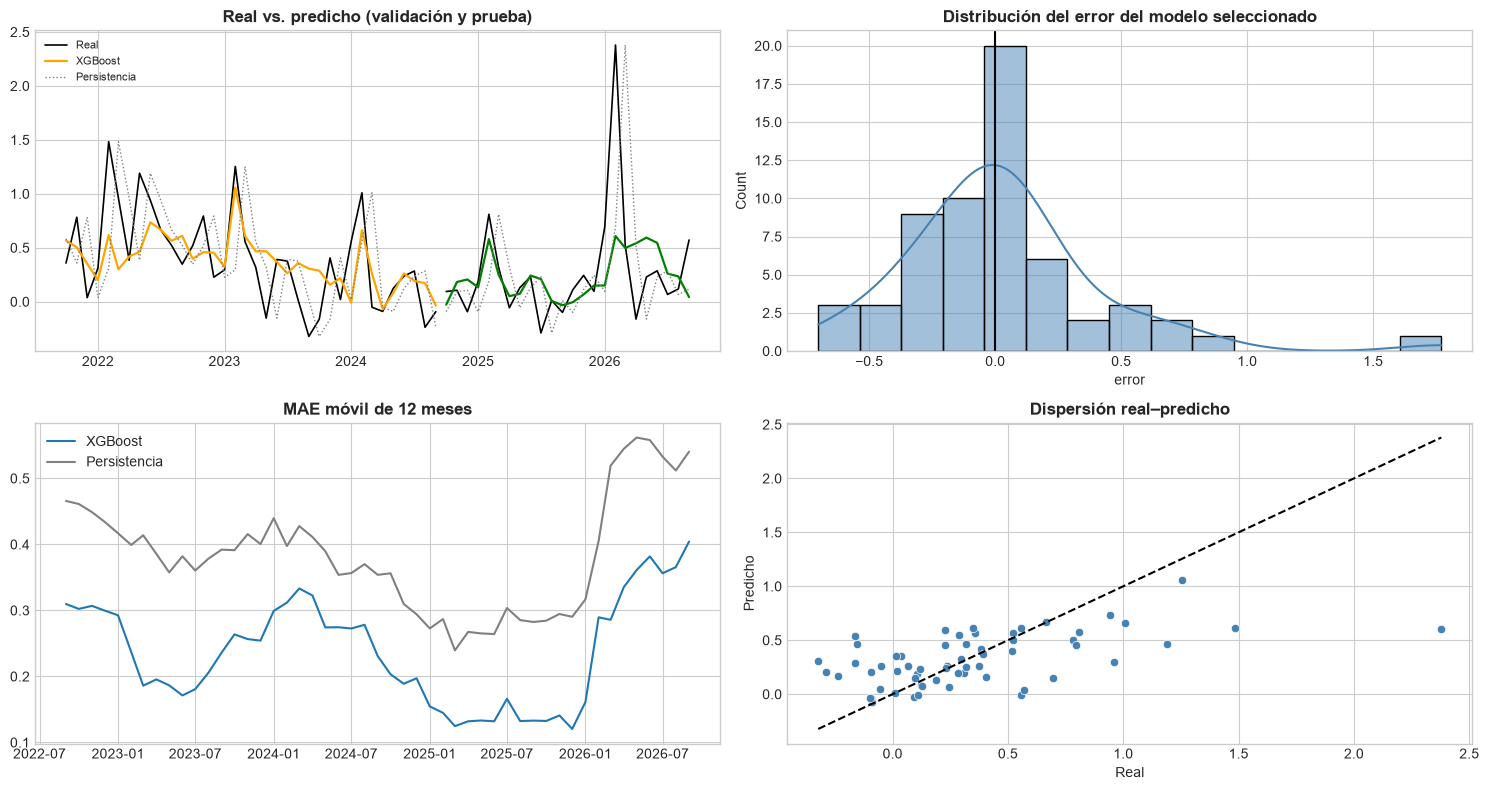

,MAE modelo,MAE persistencia,mejora %
fecha,,,
2021,0.2678,0.4652,42.4403
2022,0.2996,0.4339,30.9614
2023,0.2542,0.4005,36.5259
2024,0.1972,0.2941,32.9455
2025,0.1204,0.2903,58.5210
2026,0.5004,0.6659,24.8541


Sesgo medio del error: +0.0250 pp · Ljung-Box p(6)=0.328, p(12)=0.699 → sin autocorrelación residual relevante


In [ ]:
err_sel = (REAL - PREDS[mejor_modelo]).rename("error")
err_per = (REAL - PREDS["Persistencia"]).rename("error")
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for per, c in [(idx_val, "orange"), (idx_test, "green")]:
    ax[0, 0].plot(per, REAL.loc[per], color="k", lw=1.2)
    ax[0, 0].plot(per, PREDS[mejor_modelo].loc[per], color=c, lw=1.6)
    ax[0, 0].plot(per, PREDS["Persistencia"].loc[per], color="gray", lw=1, ls=":")
ax[0, 0].legend(["Real", mejor_modelo, "Persistencia"], fontsize=8); ax[0, 0].set_title("Real vs. predicho (validación y prueba)")
sns.histplot(err_sel, kde=True, ax=ax[0, 1], color="steelblue"); ax[0, 1].axvline(0, color="k"); ax[0, 1].set_title("Distribución del error del modelo seleccionado")
ax[1, 0].plot(err_sel.abs().rolling(12).mean(), label=mejor_modelo); ax[1, 0].plot(err_per.abs().rolling(12).mean(), label="Persistencia", color="gray")
ax[1, 0].set_title("MAE móvil de 12 meses"); ax[1, 0].legend()
sns.scatterplot(x=REAL, y=PREDS[mejor_modelo], ax=ax[1, 1], color="steelblue")
lim = [REAL.min(), REAL.max()]; ax[1, 1].plot(lim, lim, "k--"); ax[1, 1].set_xlabel("Real"); ax[1, 1].set_ylabel("Predicho"); ax[1, 1].set_title("Dispersión real–predicho")
plt.tight_layout(); plt.show()

por_anio = pd.DataFrame({"MAE modelo": err_sel.abs().groupby(err_sel.index.year).mean(),
                         "MAE persistencia": err_per.abs().groupby(err_per.index.year).mean()})
por_anio["mejora %"] = (1 - por_anio["MAE modelo"] / por_anio["MAE persistencia"]) * 100
display(por_anio)

lb = acorr_ljungbox(err_sel.dropna(), lags=[6, 12], return_df=True)
print(f"Sesgo medio del error: {err_sel.mean():+.4f} pp · Ljung-Box p(6)={lb['lb_pvalue'].iloc[0]:.3f}, p(12)={lb['lb_pvalue'].iloc[1]:.3f} "
      f"→ {'sin autocorrelación residual relevante' if lb['lb_pvalue'].min() > .05 else 'queda autocorrelación en los errores'}")

# Supuesto de generalización (validación vs prueba)
mae_v, mae_t = tab_val.loc[mejor_modelo, "MAE"], tab_test.loc[mejor_modelo, "MAE"]
razon = mae_t / mae_v
registrar("Capacidad de generalización", "MAE prueba / MAE validación del modelo seleccionado",
          f"{mejor_modelo}: {mae_v:.3f} (val) → {mae_t:.3f} (prueba); razón {razon:.2f}",
          "Sí" if razon < 1.5 else "Parcial", "Desempeño estable fuera de muestra" if razon < 1.5 else "Degradación fuera de muestra: monitorear y reentrenar")
registrar("Prevención de fuga (validación)", "assert en cada origen del walk-forward (último objetivo ≤ origen)",
          f"{len(ORIGENES)} orígenes × {len(PREDS)-len(BASES)-1} modelos sin violaciones", "Sí", "Evaluación fuera de muestra genuina")

## 13. Interpretabilidad del modelo (criterio de éxito 5)

Importancia por **permutación** del mejor modelo de ML: se entrena con todo lo anterior a la prueba y se mide cuánto empeora el MAE al barajar cada variable en el periodo de prueba (no depende del tipo de algoritmo).

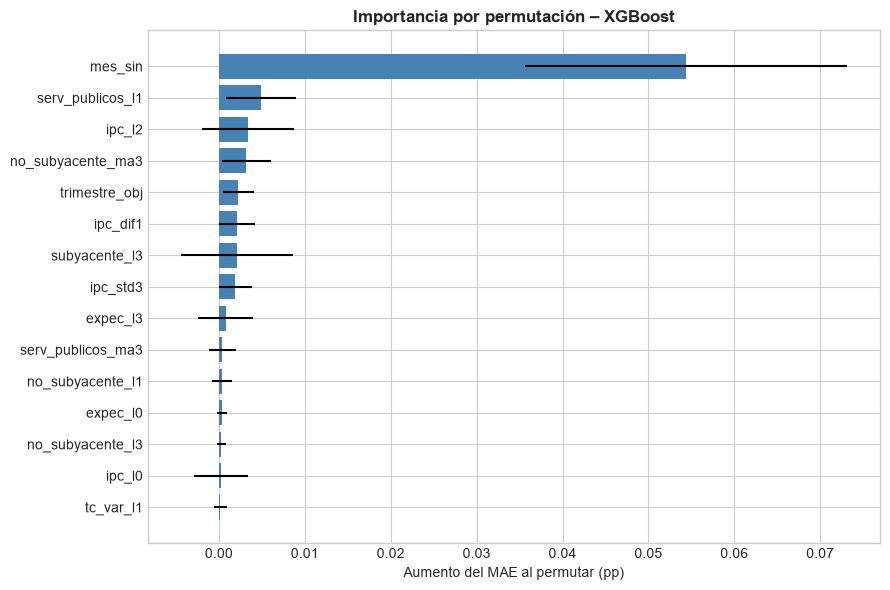

Variables más influyentes: mes_sin, serv_publicos_l1, ipc_l2, no_subyacente_ma3, trimestre_obj
(SHAP no instalado: se omite; la importancia por permutación ya cubre el criterio de interpretabilidad.)


In [ ]:
modelo_interp = clone(MODELOS_ML[mejor_ml]) if mejor_ml in MODELOS_ML else clone(MODELOS_ML["Random Forest"])
nombre_interp = mejor_ml if mejor_ml in MODELOS_ML else "Random Forest"
modelo_interp.fit(X_m.iloc[:pos_ini_test], y_m.iloc[:pos_ini_test])
pi = permutation_importance(modelo_interp, X_m.iloc[pos_ini_test:], y_m.iloc[pos_ini_test:],
                            scoring="neg_mean_absolute_error", n_repeats=50, random_state=SEED)
imp = pd.DataFrame({"variable": X_m.columns, "importancia (ΔMAE)": pi.importances_mean, "desv.": pi.importances_std}).sort_values("importancia (ΔMAE)", ascending=False)
imp.to_csv(OUT / "importancia_variables.csv", index=False)

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(9, 6)); plt.barh(top["variable"], top["importancia (ΔMAE)"], xerr=top["desv."], color="steelblue")
plt.title(f"Importancia por permutación – {nombre_interp}"); plt.xlabel("Aumento del MAE al permutar (pp)"); plt.tight_layout(); plt.show()
print("Variables más influyentes:", ", ".join(imp.head(5)["variable"]))

# Coeficientes si el modelo es lineal
if nombre_interp in ("Ridge", "Lasso"):
    coef = pd.Series(modelo_interp.named_steps["modelo"].coef_, index=X_m.columns).sort_values(key=abs, ascending=False)
    print("\nCoeficientes estandarizados más grandes:"); display(coef.head(8).to_frame("coef."))
    if nombre_interp == "Lasso":
        print(f"Lasso conservó {(coef != 0).sum()} de {len(coef)} variables.")

# SHAP (opcional; solo si la librería está instalada y el modelo es de árboles)
try:
    if nombre_interp in ("Random Forest", "XGBoost"):
        sv = shap.TreeExplainer(modelo_interp).shap_values(X_m.iloc[pos_ini_test:])
        shap.summary_plot(sv, X_m.iloc[pos_ini_test:], show=True, max_display=12)
except ImportError:
    print("(SHAP no instalado: se omite; la importancia por permutación ya cubre el criterio de interpretabilidad.)")
except Exception as e:
    print("(SHAP omitido:", type(e).__name__, ")")

## 14. Motor de alertas (Etapas 10 y 11)

Regla (secciones 6.6 y 8.17 de la tesis), con $P_{33}$ y $P_{67}$ del **conjunto de entrenamiento de cada ventana**:

$$\text{Alerta}(\hat\pi)=\begin{cases}\text{Baja}&\hat\pi\le P_{33}\\ \text{Media}&P_{33}<\hat\pi\le P_{67}\\ \text{Alta}&\hat\pi>P_{67}\end{cases}$$

El valor *observado* se clasifica con **los mismos umbrales** del origen correspondiente, de modo que predicción y realidad se comparan en la misma escala.

> **Interpretación:** al definirse por percentiles, las categorías son *relativas a la historia* (≈ 33 % de los meses cae en cada una) y **no** umbrales oficiales de riesgo inflacionario.

### 14.1 Cálculo de P33 y P67 en cada ventana

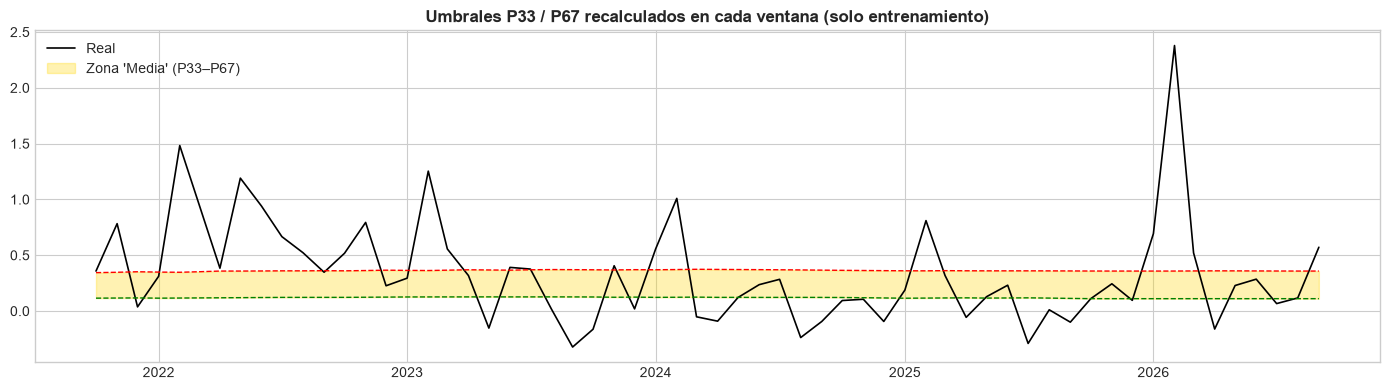

Distribución de la clase real en validación+prueba:
 clase_real
Baja     22
Media    15
Alta     23


In [ ]:
def umbrales_en_origen(i, y=None):
    """P33 y P67 con SOLO los objetivos del conjunto de entrenamiento del origen i."""
    y = y_m if y is None else y
    ytr = y.iloc[:i]
    return float(ytr.quantile(Q_BAJO)), float(ytr.quantile(Q_ALTO))

def clasificar(valor, p33, p67):
    v, a, b = (np.asarray(x, dtype=float) for x in (valor, p33, p67))
    return np.where(v <= a, "Baja", np.where(v <= b, "Media", "Alta"))

UMB = pd.DataFrame([umbrales_en_origen(i) for i in ORIGENES], index=fechas_orig, columns=["P33", "P67"])
CLASE_REAL = pd.Series(clasificar(REAL, UMB["P33"], UMB["P67"]), index=fechas_orig, name="clase_real")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(REAL.index, REAL, color="k", lw=1.2, label="Real")
ax.fill_between(UMB.index, UMB["P33"], UMB["P67"], color="gold", alpha=.3, label="Zona 'Media' (P33–P67)")
ax.plot(UMB.index, UMB["P33"], color="green", ls="--", lw=1); ax.plot(UMB.index, UMB["P67"], color="red", ls="--", lw=1)
ax.set_title("Umbrales P33 / P67 recalculados en cada ventana (solo entrenamiento)"); ax.legend(); plt.tight_layout(); plt.show()
print("Distribución de la clase real en validación+prueba:\n", CLASE_REAL.value_counts().reindex(NIVELES).to_string())

### 14.2 Clasificación de las predicciones y métricas (Etapa 9)

--------------------------------------------------------------------------------
VALIDACIÓN – calidad de la alerta


,accuracy,F1 macro,precision Alta,recall Alta,F1 Alta,n Alta real,errores graves (Alta↔Baja)
XGBoost,0.5833,0.5196,0.7778,0.7778,0.7778,18.0000,2.0000
Ridge,0.5556,0.4890,0.8125,0.7222,0.7647,18.0000,2.0000
Random Forest,0.5556,0.4842,0.7000,0.7778,0.7368,18.0000,3.0000
Ensamble ML,0.5556,0.4745,0.7368,0.7778,0.7568,18.0000,3.0000
Persistencia,0.5278,0.4702,0.6316,0.6667,0.6486,18.0000,7.0000
SARIMA,0.5000,0.4259,0.6500,0.7222,0.6842,18.0000,3.0000
Lasso,0.4444,0.4097,0.7143,0.5556,0.6250,18.0000,1.0000
Naive estacional,0.4722,0.3754,0.5909,0.7222,0.6500,18.0000,7.0000
"ARIMA(1,0,1)",0.3056,0.2766,0.5000,0.3333,0.4000,18.0000,4.0000
Media histórica,0.1944,0.1085,0.0000,0.0000,0.0000,18.0000,0.0000


--------------------------------------------------------------------------------
PRUEBA – calidad de la alerta


,accuracy,F1 macro,precision Alta,recall Alta,F1 Alta,n Alta real,errores graves (Alta↔Baja)
SARIMA,0.7500,0.7354,0.7500,0.6000,0.6667,5.0000,1.0000
Naive estacional,0.6250,0.5759,0.5000,0.4000,0.4444,5.0000,2.0000
Ensamble ML,0.5000,0.5156,0.6000,0.6000,0.6000,5.0000,1.0000
XGBoost,0.5000,0.5054,0.5000,0.6000,0.5455,5.0000,2.0000
Lasso,0.4583,0.4219,0.5000,0.2000,0.2857,5.0000,0.0000
Random Forest,0.4167,0.4172,0.4000,0.4000,0.4000,5.0000,1.0000
Persistencia,0.4167,0.4054,0.5000,0.4000,0.4444,5.0000,2.0000
Ridge,0.4167,0.3910,0.5000,0.2000,0.2857,5.0000,0.0000
"ARIMA(1,0,1)",0.4167,0.3889,0.6667,0.4000,0.5000,5.0000,0.0000
Media histórica,0.3333,0.1667,0.0000,0.0000,0.0000,5.0000,0.0000



Matriz de confusión – XGBoost (validación+prueba; filas = real, columnas = alerta emitida)


,alerta Baja,alerta Media,alerta Alta
real Baja,8,12,2
real Media,2,8,5
real Alta,2,4,17


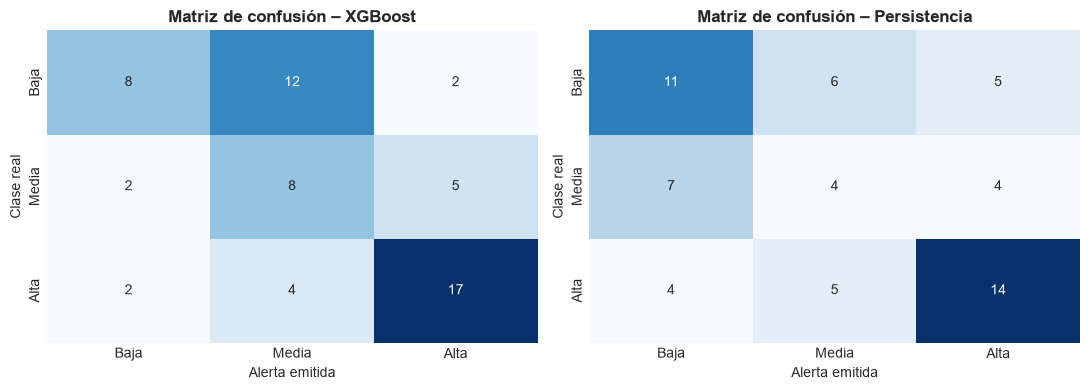

Detección de alertas ALTAS por XGBoost: recall=0.74, precisión=0.71 (persistencia: recall=0.61).


In [ ]:
def evaluar_alertas(nombre, idx):
    cp = pd.Series(clasificar(PREDS[nombre].loc[idx], UMB.loc[idx, "P33"], UMB.loc[idx, "P67"]), index=idx)
    cr = CLASE_REAL.loc[idx]
    p, r, f, s = precision_recall_fscore_support(cr, cp, labels=NIVELES, zero_division=0)
    cm = confusion_matrix(cr, cp, labels=NIVELES)
    return {"accuracy": accuracy_score(cr, cp), "F1 macro": f.mean(),
            "precision Alta": p[2], "recall Alta": r[2], "F1 Alta": f[2], "n Alta real": int(s[2]),
            "errores graves (Alta↔Baja)": int(cm[0, 2] + cm[2, 0])}, cm, cp

def tabla_alertas(idx):
    return pd.DataFrame({k: evaluar_alertas(k, idx)[0] for k in PREDS}).T.sort_values("F1 macro", ascending=False)

ta_val, ta_test = tabla_alertas(idx_val), tabla_alertas(idx_test)
linea(); print("VALIDACIÓN – calidad de la alerta"); display(ta_val)
linea(); print("PRUEBA – calidad de la alerta"); display(ta_test)

idx_vt = idx_val.append(idx_test)
res_sel, cm_sel, cp_sel = evaluar_alertas(mejor_modelo, idx_vt)
res_per, cm_per, _ = evaluar_alertas("Persistencia", idx_vt)
print(f"\nMatriz de confusión – {mejor_modelo} (validación+prueba; filas = real, columnas = alerta emitida)")
display(pd.DataFrame(cm_sel, index=[f"real {n}" for n in NIVELES], columns=[f"alerta {n}" for n in NIVELES]))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, cm_, t_ in [(ax[0], cm_sel, mejor_modelo), (ax[1], cm_per, "Persistencia")]:
    sns.heatmap(cm_, annot=True, fmt="d", cmap="Blues", xticklabels=NIVELES, yticklabels=NIVELES, ax=a_, cbar=False)
    a_.set_title(f"Matriz de confusión – {t_}"); a_.set_xlabel("Alerta emitida"); a_.set_ylabel("Clase real")
plt.tight_layout(); plt.show()
print(f"Detección de alertas ALTAS por {mejor_modelo}: recall={res_sel['recall Alta']:.2f}, precisión={res_sel['precision Alta']:.2f} "
      f"(persistencia: recall={res_per['recall Alta']:.2f}).")
if res_sel["n Alta real"] < 15:
    print(f"⚠ Solo hay {res_sel['n Alta real']} meses de alerta Alta reales: las métricas de esta clase son poco estables.")

### 14.3 Validación del funcionamiento del motor de alertas (Etapa 10)

In [ ]:
pruebas = []
def prueba(nombre, condicion, detalle=""):
    pruebas.append({"Prueba": nombre, "Resultado": "APROBADA" if condicion else "FALLA", "Detalle": detalle})

# P1. Umbrales calculados exclusivamente con datos de entrenamiento: si se corrompe el futuro, no cambian.
rng = np.random.default_rng(SEED); ok = True
for i in rng.choice(ORIGENES, size=8, replace=False):
    y_corrupto = y_m.copy(); y_corrupto.iloc[i:] = 999.0                 # el "futuro" se vuelve absurdo
    ok &= np.allclose(umbrales_en_origen(i, y_corrupto), umbrales_en_origen(i))
    ok &= (y_m.index[i - 1] + pd.offsets.MonthBegin(1)) <= X_m.index[i]    # último dato usado ≤ origen
prueba("P1 · Umbrales P33/P67 solo con entrenamiento", ok, "8 orígenes aleatorios; futuro corrupto no altera los umbrales")

# P2. Se recalculan en cada ventana
prueba("P2 · Umbrales recalculados por ventana", UMB["P33"].nunique() > 1 and UMB["P67"].nunique() > 1,
       f"P33 toma {UMB['P33'].nunique()} valores distintos, P67 {UMB['P67'].nunique()}")

# P3. P33 < P67 siempre
prueba("P3 · Orden de umbrales P33 < P67", bool((UMB["P33"] < UMB["P67"]).all()))

# P4. Asignación correcta frente a una implementación independiente (bucle)
def clasificar_lento(v, a, b):
    if v <= a: return "Baja"
    if v <= b: return "Media"
    return "Alta"
muestra = PREDS[mejor_modelo]
ok = all(clasificar_lento(v, a, b) == c for v, a, b, c in
         zip(muestra, UMB["P33"], UMB["P67"], clasificar(muestra, UMB["P33"], UMB["P67"])))
prueba("P4 · Asignación de categorías (vs. implementación independiente)", ok, f"{len(muestra)} predicciones")

# P5. Pruebas de límites
a, b = 0.20, 0.45; e = 1e-9
casos = {a: "Baja", a + e: "Media", b: "Media", b + e: "Alta", a - 1: "Baja", b + 1: "Alta"}
ok = all(clasificar([v], [a], [b])[0] == esperado for v, esperado in casos.items())
prueba("P5 · Valores iguales o cercanos a P33 y P67", ok, "P33 → Baja · P33+ε → Media · P67 → Media · P67+ε → Alta")

# P6. Consistencia: una categoría válida para cada predicción válida
cls_todas = {k: clasificar(PREDS[k], UMB["P33"], UMB["P67"]) for k in PREDS}
ok = all(set(v) <= set(NIVELES) and len(v) == PREDS[k].notna().sum() for k, v in cls_todas.items())
prueba("P6 · Una categoría válida por predicción", ok, f"{len(cls_todas)} modelos × {len(fechas_orig)} orígenes")

# P7. Comparación con el valor observado (métricas de clasificación disponibles)
prueba("P7 · Evaluación frente al observado (métricas y matriz)", cm_sel.sum() == len(idx_vt), f"matriz con {int(cm_sel.sum())} casos")

resultado_pruebas = pd.DataFrame(pruebas)
display(resultado_pruebas)
assert (resultado_pruebas["Resultado"] == "APROBADA").all(), "El motor de alertas no supera todas las pruebas"
print("Motor de alertas validado:", len(resultado_pruebas), "pruebas aprobadas.")

,Prueba,Resultado,Detalle
0,P1 · Umbrales P33/P67 solo con entrenamiento,APROBADA,8 orígenes aleatorios; futuro corrupto no alte...
1,P2 · Umbrales recalculados por ventana,APROBADA,"P33 toma 60 valores distintos, P67 60"
2,P3 · Orden de umbrales P33 < P67,APROBADA,
3,P4 · Asignación de categorías (vs. implementac...,APROBADA,60 predicciones
4,P5 · Valores iguales o cercanos a P33 y P67,APROBADA,P33 → Baja · P33+ε → Media · P67 → Media · P67...
5,P6 · Una categoría válida por predicción,APROBADA,10 modelos × 60 orígenes
6,P7 · Evaluación frente al observado (métricas ...,APROBADA,matriz con 60 casos


Motor de alertas validado: 7 pruebas aprobadas.


---
## 15. Simulación operativa: pronóstico del próximo mes (Etapa 11)

1. Se re-entrena el modelo seleccionado con **toda** la historia disponible.
2. Se pronostica $\pi_{t+1}$ desde el último origen.
3. El intervalo se obtiene por **remuestreo (Monte Carlo)** de los errores fuera de muestra del propio modelo (validación + prueba).
4. Umbrales P33/P67 con toda la historia conocida (en operación, todo el pasado es "entrenamiento").

In [ ]:
def ajustar_y_predecir_final(nombre):
    """Reentrena con todo el histórico y pronostica desde X_live. Devuelve (pronóstico, objeto del modelo)."""
    if nombre in MODELOS_ML:
        m = clone(MODELOS_ML[nombre]).fit(X_m, y_m)
        return float(m.predict(X_live)[0]), m
    if nombre == "Ensamble ML":
        ms = {k: clone(v).fit(X_m, y_m) for k, v in MODELOS_ML.items()}
        return float(np.mean([m.predict(X_live)[0] for m in ms.values()])), ms
    if nombre in MODELOS_TS:
        esp = MODELOS_TS[nombre]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = SARIMAX(ipc.to_numpy(), order=esp["order"], seasonal_order=esp["seasonal_order"], trend="c",
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        return float(np.asarray(res.forecast(1))[0]), res
    if nombre in BASES:                                       # si la mejor opción fuera una línea base
        ult = {"Persistencia": float(X_live["ipc_l0"].iloc[0]),
               "Naive estacional": float(ipc.iloc[-11]), "Media histórica": float(y_m.mean())}
        return ult[nombre], None
    raise KeyError(nombre)

pred_live, objeto_modelo = ajustar_y_predecir_final(mejor_modelo)

# Intervalo predictivo empírico (Monte Carlo sobre errores fuera de muestra)
residuos = (REAL - PREDS[mejor_modelo]).dropna().to_numpy()
assert len(residuos) >= 8
rng = np.random.default_rng(SEED)
sim = pred_live + rng.choice(residuos, size=N_SIMULACIONES, replace=True)
p05, p50, p95 = np.quantile(sim, [.05, .5, .95])

P33_f, P67_f = float(y_m.quantile(Q_BAJO)), float(y_m.quantile(Q_ALTO))
prob = pd.Series({"Baja": np.mean(sim <= P33_f), "Media": np.mean((sim > P33_f) & (sim <= P67_f)), "Alta": np.mean(sim > P67_f)})
alerta_puntual = str(clasificar([pred_live], [P33_f], [P67_f])[0])
alerta_probable = prob.idxmax()

linea(); print("PRONÓSTICO OPERATIVO")
print(f"Modelo seleccionado       : {mejor_modelo}")
print(f"Origen (último IPC)       : {fecha_origen_live:%Y-%m}  →  IPC observado = {ipc.iloc[-1]:.3f}%")
print(f"Mes pronosticado          : {fecha_objetivo_live:%Y-%m}")
print(f"Inflación estimada        : {pred_live:.3f}%   (intervalo empírico 90 %: [{p05:.3f}%, {p95:.3f}%])")
print(f"Umbrales (toda la historia): P33={P33_f:.3f}%  P67={P67_f:.3f}%")
print(f"NIVEL DE ALERTA (estimación puntual): {alerta_puntual.upper()}")
print(f"Nivel más probable (simulación)     : {alerta_probable}")
display(prob.rename("Probabilidad").to_frame().style.format("{:.1%}"))
margen = min(abs(pred_live - P33_f), abs(pred_live - P67_f))
if margen < tab_val.loc[mejor_modelo, "MAE"]:
    print(f"⚠ La estimación está a {margen:.3f} pp de un umbral (menos que el MAE de validación, {tab_val.loc[mejor_modelo,'MAE']:.3f} pp): "
          "la categoría es poco robusta; considere las probabilidades.")

if mejor_modelo in MODELOS_ML:        # Explicación: valores actuales de las variables más influyentes
    top5 = imp.head(5)["variable"]
    expl = pd.DataFrame({"valor actual": X_live[top5].iloc[0],
                         "percentil histórico (%)": [stats.percentileofscore(X_m[c], X_live[c].iloc[0]) for c in top5]})
    print("\nExplicación: situación actual de las variables más influyentes"); display(expl)

--------------------------------------------------------------------------------
PRONÓSTICO OPERATIVO
Modelo seleccionado       : XGBoost
Origen (último IPC)       : 2026-10  →  IPC observado = 0.571%
Mes pronosticado          : 2026-11
Inflación estimada        : 0.363%   (intervalo empírico 90 %: [-0.136%, 1.092%])
Umbrales (toda la historia): P33=0.111%  P67=0.359%
NIVEL DE ALERTA (estimación puntual): ALTA
Nivel más probable (simulación)     : Alta


,Probabilidad
Baja,21.7%
Media,29.8%
Alta,48.6%


⚠ La estimación está a 0.005 pp de un umbral (menos que el MAE de validación, 0.259 pp): la categoría es poco robusta; considere las probabilidades.

Explicación: situación actual de las variables más influyentes


,valor actual,percentil histórico (%)
mes_sin,-0.5000,29.5019
serv_publicos_l1,0.1282,56.7050
ipc_l2,0.0668,27.2031
no_subyacente_ma3,0.4164,63.6015
trimestre_obj,4.0000,87.9310


---
# FASE 6 — Despliegue
## 16. Exportación de resultados y persistencia del modelo

In [ ]:
# 16.1 Predicciones fuera de muestra (todos los modelos)
oos = pd.DataFrame({"periodo_objetivo": (fechas_orig + pd.offsets.MonthBegin(1)).strftime("%Y-%m"),
                    "periodo_muestra": np.where(fechas_orig.isin(idx_val), "validación", "prueba"),
                    "real": REAL.values, "P33": UMB["P33"].values, "P67": UMB["P67"].values,
                    "clase_real": CLASE_REAL.values}, index=fechas_orig)
for k in PREDS:
    oos[f"pred_{k}"] = PREDS[k].values
oos[f"alerta_{mejor_modelo}"] = clasificar(PREDS[mejor_modelo], UMB["P33"], UMB["P67"])
oos.index.name = "fecha_origen"
oos.to_csv(OUT / "predicciones_fuera_de_muestra.csv", encoding="utf-8-sig")

# 16.2 Serie histórica para el dashboard
df_base[["ipc"]].rename_axis("fecha").to_csv(OUT / "serie_historica_ipc.csv")

# 16.3 Pronóstico operativo
pron = {"fecha_emision": datetime.now().strftime("%Y-%m-%d"), "modelo": mejor_modelo,
        "origen": f"{fecha_origen_live:%Y-%m}", "periodo_objetivo": f"{fecha_objetivo_live:%Y-%m}",
        "ipc_observado_origen": float(ipc.iloc[-1]), "prediccion": pred_live, "p05": float(p05), "p50": float(p50), "p95": float(p95),
        "P33": P33_f, "P67": P67_f, "alerta": alerta_puntual, "alerta_mas_probable": alerta_probable,
        "prob_baja": float(prob["Baja"]), "prob_media": float(prob["Media"]), "prob_alta": float(prob["Alta"]),
        "mae_validacion": float(tab_val.loc[mejor_modelo, "MAE"]), "mae_prueba": float(tab_test.loc[mejor_modelo, "MAE"])}
(OUT / "pronostico_operativo.json").write_text(json.dumps(pron, indent=2, ensure_ascii=False), encoding="utf-8")

# 16.4 Métricas y supuestos
pd.concat({"validacion": tab_val, "prueba": tab_test}).to_csv(OUT / "metricas_modelos.csv", encoding="utf-8-sig")
pd.concat({"validacion": ta_val, "prueba": ta_test}).to_csv(OUT / "metricas_alertas.csv", encoding="utf-8-sig")
pd.DataFrame(SUPUESTOS).to_csv(OUT / "evaluacion_supuestos.csv", index=False, encoding="utf-8-sig")
resultado_pruebas.to_csv(OUT / "pruebas_motor_alertas.csv", index=False, encoding="utf-8-sig")

# 16.5 Persistencia del modelo
joblib.dump({"nombre": mejor_modelo, "modelo": objeto_modelo, "variables": list(X_m.columns),
             "umbrales": {"P33": P33_f, "P67": P67_f}, "entrenado_hasta": f"{X_m.index[-1]:%Y-%m}",
             "version_pandas": pd.__version__}, OUT / "modelo_alerta_inflacion.joblib")

print("Archivos generados en", OUT.resolve())
for f in sorted(OUT.glob("*.*")):
    print(f"  · {f.name:42s} {f.stat().st_size/1024:8.1f} KB")

Archivos generados en C:\Users\LENOVO\Documents\GLOBAL\octubre\salidas_alerta_inflacion
  · app_streamlit.py                                2.5 KB
  · dashboard_alerta_inflacion.html                45.6 KB
  · evaluacion_supuestos.csv                        1.4 KB
  · importancia_variables.csv                       2.3 KB
  · matriz_recoleccion_datos.csv                  287.9 KB
  · metricas_alertas.csv                            2.0 KB
  · metricas_modelos.csv                            2.1 KB
  · modelo_alerta_inflacion.joblib                273.7 KB
  · predicciones_fuera_de_muestra.csv              17.3 KB
  · pronostico_operativo.json                       0.5 KB
  · pruebas_motor_alertas.csv                       0.7 KB
  · registro_predicciones.csv                       0.2 KB
  · serie_historica_ipc.csv                         8.1 KB


### 16.6 Registro mensual de predicciones (ciclo de retroalimentación – sección 4.2 de la tesis)
Cada ejecución **agrega** (o actualiza) el pronóstico emitido y **completa el valor observado** de los meses ya publicados, para monitorear el error real del sistema en operación.

In [ ]:
reg_path = OUT / "registro_predicciones.csv"
nuevo = {"fecha_emision": pron["fecha_emision"], "periodo_objetivo": pron["periodo_objetivo"], "modelo": mejor_modelo,
         "prediccion": round(pred_live, 4), "p05": round(float(p05), 4), "p95": round(float(p95), 4),
         "P33": round(P33_f, 4), "P67": round(P67_f, 4), "alerta_emitida": alerta_puntual}
reg = pd.read_csv(reg_path) if reg_path.exists() else pd.DataFrame(columns=list(nuevo) + ["observado", "alerta_observada", "error"])
reg = reg[reg["periodo_objetivo"] != nuevo["periodo_objetivo"]]
reg = pd.concat([reg, pd.DataFrame([nuevo])], ignore_index=True)
obs = {f"{d:%Y-%m}": v for d, v in ipc.items()}
reg["observado"] = reg["periodo_objetivo"].map(obs)
reg["alerta_observada"] = [clasificar([o], [a], [b])[0] if pd.notna(o) else np.nan for o, a, b in zip(reg["observado"], reg["P33"], reg["P67"])]
reg["error"] = reg["observado"] - reg["prediccion"]
reg = reg.sort_values("periodo_objetivo").reset_index(drop=True)
reg.to_csv(reg_path, index=False, encoding="utf-8-sig")
display(reg.tail(6))

,fecha_emision,periodo_objetivo,modelo,prediccion,p05,p95,P33,P67,alerta_emitida,observado,alerta_observada,error
0,2026-11-06,2026-11,XGBoost,0.3634,-0.1365,1.0924,0.1110,0.3587,Alta,NaN,NaN,NaN


## 17. Dashboard interactivo (Etapa 12)

Muestra la evolución histórica, la estimación del mes siguiente con su nivel de alerta, las probabilidades por nivel, la comparación predicción-observado, la matriz de confusión y las variables más influyentes. El menú desplegable permite alternar el modelo mostrado. Se guarda también como HTML independiente.

In [ ]:
COL_ALERTA = {"Baja": "#2e9e5b", "Media": "#f0a30a", "Alta": "#d64545"}
hist_desde = df_base.index[-120]
h = df_base.loc[hist_desde:, "ipc"]

fig = make_subplots(rows=3, cols=2, row_heights=[.42, .26, .32], vertical_spacing=.11, horizontal_spacing=.1,
                    specs=[[{"colspan": 2}, None], [{}, {}], [{}, {"type": "table"}]],
                    subplot_titles=("Inflación mensual: real, predicciones fuera de muestra y pronóstico",
                                    "Probabilidad por nivel de alerta (próximo mes)",
                                    f"Matriz de confusión – {mejor_modelo} (validación + prueba)",
                                    "Variables más influyentes (importancia por permutación)",
                                    "Últimas predicciones vs. observado"))
fig.add_trace(go.Scatter(x=h.index, y=h.values, name="IPC observado", mode="lines", line=dict(color="#1f3b73", width=2)), 1, 1)
modelos_dash = list(PREDS)
for k in modelos_dash:
    fig.add_trace(go.Scatter(x=fechas_orig + pd.offsets.MonthBegin(1), y=PREDS[k].values, name=k, mode="lines+markers",
                             line=dict(width=1.6, dash="dot" if k in LINEAS_BASE else "solid"), marker=dict(size=4),
                             visible=(k in (mejor_modelo, "Persistencia"))), 1, 1)
n_antes = 1 + len(modelos_dash)
fig.add_trace(go.Scatter(x=[fecha_objetivo_live], y=[pred_live], name=f"Pronóstico {fecha_objetivo_live:%Y-%m}", mode="markers",
                         marker=dict(size=14, color=COL_ALERTA[alerta_puntual], symbol="diamond", line=dict(width=2, color="black")),
                         error_y=dict(type="data", symmetric=False, array=[p95 - pred_live], arrayminus=[pred_live - p05])), 1, 1)
fig.add_hline(y=P33_f, line=dict(color="green", dash="dash", width=1), annotation_text="P33", row=1, col=1)
fig.add_hline(y=P67_f, line=dict(color="red", dash="dash", width=1), annotation_text="P67", row=1, col=1)

fig.add_trace(go.Bar(x=NIVELES, y=[prob[n] for n in NIVELES], marker_color=[COL_ALERTA[n] for n in NIVELES],
                     text=[f"{prob[n]:.0%}" for n in NIVELES], textposition="outside", showlegend=False), 2, 1)
fig.add_trace(go.Heatmap(z=cm_sel, x=[f"Alerta {n}" for n in NIVELES], y=[f"Real {n}" for n in NIVELES], colorscale="Blues",
                         text=cm_sel, texttemplate="%{text}", showscale=False), 2, 2)
topi = imp.head(10).iloc[::-1]
fig.add_trace(go.Bar(x=topi["importancia (ΔMAE)"], y=topi["variable"], orientation="h", marker_color="#4c78a8", showlegend=False), 3, 1)
ult = oos.tail(12)[::-1]
fig.add_trace(go.Table(header=dict(values=["Mes", "Real %", "Predicho %", "Alerta real", "Alerta emitida"], fill_color="#1f3b73", font=dict(color="white")),
                       cells=dict(values=[ult["periodo_objetivo"], ult["real"].round(3), ult[f"pred_{mejor_modelo}"].round(3), ult["clase_real"], ult[f"alerta_{mejor_modelo}"]])), 3, 2)

botones = []
for k in modelos_dash:
    vis = [True] * len(fig.data)
    for j, m_ in enumerate(modelos_dash):
        vis[1 + j] = (m_ == k) or (m_ == "Persistencia")
    botones.append(dict(label=k, method="update", args=[{"visible": vis}]))
fig.update_layout(
    title=dict(text=(f"<b>Alerta temprana de inflación – Lima Metropolitana</b><br>"
                     f"Pronóstico {fecha_objetivo_live:%Y-%m}: <b>{pred_live:.2f}%</b> "
                     f"[{p05:.2f}% ; {p95:.2f}%] → "
                     f"<span style='color:{COL_ALERTA[alerta_puntual]}'><b>ALERTA {alerta_puntual.upper()}</b></span>"
                     f"<br><sup>Modelo: {mejor_modelo} · emitido {pron['fecha_emision']} · prototipo académico, no sustituye estadísticas oficiales</sup>"),
               x=.01, xanchor="left"),
    updatemenus=[dict(buttons=botones, direction="down", x=1.0, xanchor="right", y=1.17, yanchor="top", active=modelos_dash.index(mejor_modelo))],
    height=980, template="plotly_white", legend=dict(orientation="h", y=-0.04), margin=dict(t=150))
fig.update_yaxes(title_text="% mensual", row=1, col=1); fig.update_yaxes(tickformat=".0%", range=[0, 1.1], row=2, col=1)
fig.write_html(OUT / "dashboard_alerta_inflacion.html", include_plotlyjs="cdn")
fig.show()
print("Dashboard guardado en", (OUT / "dashboard_alerta_inflacion.html").resolve())

Dashboard guardado en C:\Users\LENOVO\Documents\GLOBAL\octubre\salidas_alerta_inflacion\dashboard_alerta_inflacion.html


### 17.1 Versión Streamlit (para publicar como aplicación web)
La celda genera `app_streamlit.py`, que lee los archivos exportados. Para ejecutarla: `pip install streamlit plotly pandas` y luego `streamlit run salidas_alerta_inflacion/app_streamlit.py`.

In [ ]:
APP = """
import json
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go
import streamlit as st

D = Path(__file__).parent
st.set_page_config(page_title="Alerta temprana de inflación – Lima", layout="wide")
p = json.loads((D / "pronostico_operativo.json").read_text(encoding="utf-8"))
hist = pd.read_csv(D / "serie_historica_ipc.csv", parse_dates=["fecha"])
oos = pd.read_csv(D / "predicciones_fuera_de_muestra.csv")
reg = pd.read_csv(D / "registro_predicciones.csv")
imp = pd.read_csv(D / "importancia_variables.csv")
COL = {"Baja": "#2e9e5b", "Media": "#f0a30a", "Alta": "#d64545"}

st.title("Sistema de alerta temprana – inflación mensual de Lima Metropolitana")
st.caption("Prototipo académico. No sustituye las estadísticas ni evaluaciones oficiales del BCRP o del INEI.")
c1, c2, c3, c4 = st.columns(4)
c1.metric("Mes pronosticado", p["periodo_objetivo"])
c2.metric("Inflación estimada", f"{p['prediccion']:.2f} %", f"IC90 [{p['p05']:.2f}; {p['p95']:.2f}]", delta_color="off")
c3.markdown(f"### Alerta: <span style='color:{COL[p['alerta']]}'>{p['alerta'].upper()}</span>", unsafe_allow_html=True)
c4.metric("MAE (prueba)", f"{p['mae_prueba']:.3f} pp")

anios = st.slider("Años de historia", 2, 20, 10)
h = hist[hist["fecha"] >= hist["fecha"].max() - pd.DateOffset(years=anios)]
cols = [c for c in oos.columns if c.startswith("pred_")]
sel = st.multiselect("Predicciones fuera de muestra", cols, default=[f"pred_{p['modelo']}", "pred_Persistencia"])
fig = go.Figure(go.Scatter(x=h["fecha"], y=h["ipc"], name="IPC observado"))
x = pd.to_datetime(oos["periodo_objetivo"])
for c in sel:
    fig.add_trace(go.Scatter(x=x, y=oos[c], name=c.replace("pred_", ""), mode="lines+markers"))
fig.add_trace(go.Scatter(x=[pd.to_datetime(p["periodo_objetivo"])], y=[p["prediccion"]], mode="markers", name="Pronóstico",
                         marker=dict(size=14, color=COL[p["alerta"]], symbol="diamond")))
fig.add_hline(y=p["P33"], line_dash="dash", line_color="green"); fig.add_hline(y=p["P67"], line_dash="dash", line_color="red")
st.plotly_chart(fig, use_container_width=True)

a, b = st.columns(2)
a.subheader("Probabilidad por nivel")
a.bar_chart(pd.Series({"Baja": p["prob_baja"], "Media": p["prob_media"], "Alta": p["prob_alta"]}))
b.subheader("Variables más influyentes")
b.bar_chart(imp.head(10).set_index("variable")["importancia (ΔMAE)"])
st.subheader("Registro de predicciones emitidas vs. observado")
st.dataframe(reg.tail(24), use_container_width=True)
"""
(OUT / "app_streamlit.py").write_text(APP, encoding="utf-8")
import ast; ast.parse(APP)       # verifica que el código generado es sintácticamente válido
print("app_streamlit.py generada y verificada sintácticamente →", (OUT / "app_streamlit.py").resolve())

app_streamlit.py generada y verificada sintácticamente → C:\Users\LENOVO\Documents\GLOBAL\octubre\salidas_alerta_inflacion\app_streamlit.py


## 18. Conclusiones técnicas

### 18.1 Evaluación de los criterios de éxito (generada automáticamente)

In [ ]:
res_t, _, _ = evaluar_alertas(mejor_modelo, idx_test); res_per_t, _, _ = evaluar_alertas("Persistencia", idx_test)
mae_sel_t, mae_per_t = tab_test.loc[mejor_modelo, "MAE"], tab_test.loc["Persistencia", "MAE"]
rm_sel_t,  rm_per_t  = tab_test.loc[mejor_modelo, "RMSE"], tab_test.loc["Persistencia", "RMSE"]
ml_mejor_val = tab_val.loc[list(MODELOS_ML) + ["Ensamble ML"], "MAE"].min()
ml_mejora_val = ml_mejor_val < tab_val.loc["Persistencia", "MAE"]
ml_mejora_test = tab_test.loc[list(MODELOS_ML) + ["Ensamble ML"], "MAE"].min() < mae_per_t
criterios = pd.DataFrame([
    ("1. Superar a la persistencia (ML)", f"Mejor ML val: MAE {ml_mejor_val:.3f} vs persistencia {tab_val.loc['Persistencia','MAE']:.3f}; "
     f"prueba: mejor ML {tab_test.loc[list(MODELOS_ML)+['Ensamble ML'],'MAE'].min():.3f} vs {mae_per_t:.3f}; DM significativo en: {mejoran or 'ninguno'}",
     "Sí" if (ml_mejora_val and ml_mejora_test and mejoran) else ("Parcial" if (ml_mejora_val or ml_mejora_test) else "No")),
    ("2. Metodología sin fuga", "Pruebas de truncamiento/enmascarado y asserts de walk-forward aprobados", "Sí"),
    ("3. Errores aceptables (MAE/RMSE)", f"{mejor_modelo} en prueba: MAE {mae_sel_t:.3f}, RMSE {rm_sel_t:.3f} (persistencia {mae_per_t:.3f} / {rm_per_t:.3f})",
     "Sí" if mae_sel_t < mae_per_t and rm_sel_t < rm_per_t else "Parcial" if mae_sel_t < mae_per_t or rm_sel_t < rm_per_t else "No"),
    ("4. Clasificación de alertas (Sí = exactitud ≥ 0.60 en prueba y mejor que la persistencia)",
     f"val+prueba: accuracy {res_sel['accuracy']:.2f}, F1 macro {res_sel['F1 macro']:.2f}, recall Alta {res_sel['recall Alta']:.2f} "
     f"(persistencia: {res_per['accuracy']:.2f} / {res_per['recall Alta']:.2f}); solo prueba: accuracy {res_t['accuracy']:.2f}, recall Alta {res_t['recall Alta']:.2f} "
     f"(persistencia: {res_per_t['accuracy']:.2f} / {res_per_t['recall Alta']:.2f})",
     "Sí" if (res_t["accuracy"] >= .60 and res_t["accuracy"] > res_per_t["accuracy"]) else ("Parcial" if res_sel["accuracy"] > res_per["accuracy"] else "No")),
    ("5. Interpretabilidad", f"Variables más influyentes: {', '.join(imp.head(3)['variable'])}", "Sí"),
    ("6. Dashboard interactivo", "dashboard_alerta_inflacion.html + app_streamlit.py", "Sí"),
], columns=["Criterio de éxito", "Evidencia", "Cumplimiento"]).set_index("Criterio de éxito")
pd.set_option("display.max_colwidth", 200)
display(criterios)

,Evidencia,Cumplimiento
Criterio de éxito,,
1. Superar a la persistencia (ML),"Mejor ML val: MAE 0.259 vs persistencia 0.404; prueba: mejor ML 0.246 vs 0.411; DM significativo en: ['Ridge', 'Lasso', 'Random Forest', 'XGBoost', 'Ensamble ML', 'ARIMA(1,0,1)', 'SARIMA']",Sí
2. Metodología sin fuga,Pruebas de truncamiento/enmascarado y asserts de walk-forward aprobados,Sí
3. Errores aceptables (MAE/RMSE),"XGBoost en prueba: MAE 0.269, RMSE 0.454 (persistencia 0.411 / 0.611)",Sí
4. Clasificación de alertas (Sí = exactitud ≥ 0.60 en prueba y mejor que la persistencia),"val+prueba: accuracy 0.55, F1 macro 0.53, recall Alta 0.74 (persistencia: 0.48 / 0.61); solo prueba: accuracy 0.50, recall Alta 0.60 (persistencia: 0.42 / 0.40)",Parcial
5. Interpretabilidad,"Variables más influyentes: mes_sin, serv_publicos_l1, ipc_l2",Sí
6. Dashboard interactivo,dashboard_alerta_inflacion.html + app_streamlit.py,Sí


### 16.2 Resumen de supuestos y condiciones de modelamiento (Etapa 4)

In [ ]:
tabla_supuestos = pd.DataFrame(SUPUESTOS).set_index("Supuesto")
display(tabla_supuestos)

,Prueba,Resultado,¿Cumple?,Implicación
Supuesto,,,,
Consistencia temporal,"Continuidad, duplicados y NaN del IPC","0 faltantes, 0 duplicados, 0 NaN",Sí,Serie mensual continua; no se requiere imputación del objetivo
Disponibilidad de indicadores,Comparación día de publicación vs. día de emisión (5),"Rezago de 1 mes en: ipm, expectativa_12m",Sí (por construcción),Cada variable se desplaza según su fecha de publicación; verificar calendarios oficiales (supuesto)
Estabilidad (media / varianza / cambios estructurales),"Welch, Levene y CUSUM",p(media)=0.441; p(varianza)=0.149; p(CUSUM)=0.074,Sí,Régimen estable
Estacionariedad,ADF + KPSS (IPC y predictores),IPC: Estacionaria; no estacionarias: ninguna,Sí,Los modelos pueden trabajar con la serie en niveles de variación mensual
Estacionalidad,STL (periodo 12) – fuerza estacional,Fuerza = 0.48,Sí,Se incluyen mes (seno/coseno) y rezago anual
Prevención de fuga (variables),Truncamiento y enmascarado en 12 orígenes aleatorios,Variables idénticas con datos truncados,Sí,Las características no usan información posterior al origen
Capacidad de generalización,MAE prueba / MAE validación del modelo seleccionado,XGBoost: 0.259 (val) → 0.269 (prueba); razón 1.04,Sí,Desempeño estable fuera de muestra
Prevención de fuga (validación),assert en cada origen del walk-forward (último objetivo ≤ origen),60 orígenes × 6 modelos sin violaciones,Sí,Evaluación fuera de muestra genuina


In [ ]:
print("CONCLUSIONES")
linea()
print(f"• Con {N} observaciones mensuales ({X_m.index[0]:%Y-%m}–{X_m.index[-1]:%Y-%m}) y {X_m.shape[1]} variables, el mejor candidato en validación fue {mejor_modelo}.")
if mejoran:
    print(f"• Hay evidencia estadística (Diebold-Mariano, α=5 %) de mejora frente a la persistencia para: {', '.join(mejoran)}.")
else:
    print("• La mejora frente a la persistencia NO es estadísticamente significativa: no se rechaza H₀ con esta muestra.")
print(f"• Sobre la prueba final ({idx_test[0]:%Y-%m}–{idx_test[-1]:%Y-%m}) el modelo seleccionado obtuvo MAE={mae_sel_t:.3f} pp frente a {mae_per_t:.3f} pp de la persistencia.")
print(f"• Alerta emitida para {fecha_objetivo_live:%Y-%m}: {alerta_puntual.upper()} (estimación {pred_live:.2f} %, IC90 [{p05:.2f}; {p95:.2f}]).")
print("""
LIMITACIONES
• Los niveles Baja/Media/Alta son relativos a la distribución histórica (percentiles), no umbrales oficiales de riesgo.
• Los días de publicación de IPM y de la encuesta de expectativas son supuestos conservadores: verificar con los calendarios oficiales del BCRP/INEI.
• ~60 meses de evaluación y pocos meses de alerta Alta reales → métricas de clasificación y pruebas de significancia con baja potencia.
• La inflación puede ser afectada por choques de oferta (clima, combustibles, eventos extraordinarios) no recogidos por los indicadores.
• Las series pueden ser revisadas por las instituciones; el registro mensual permite auditar las predicciones emitidas.

TRABAJO FUTURO
• Incorporar variables exclusivas del INEI y de precios internacionales (petróleo, alimentos) y de clima.
• Evaluar horizontes de 2 a 3 meses y pronóstico de la inflación interanual.
• Afinar hiperparámetros con validación anidada y evaluar modelos clasificatorios directos para la clase Alta.
• Automatizar la ejecución mensual (cron / GitHub Actions) y alertas por correo.
""")

CONCLUSIONES
--------------------------------------------------------------------------------
• Con 261 observaciones mensuales (2005-01–2026-09) y 43 variables, el mejor candidato en validación fue XGBoost.
• Hay evidencia estadística (Diebold-Mariano, α=5 %) de mejora frente a la persistencia para: Ridge, Lasso, Random Forest, XGBoost, Ensamble ML, ARIMA(1,0,1), SARIMA.
• Sobre la prueba final (2024-10–2026-09) el modelo seleccionado obtuvo MAE=0.269 pp frente a 0.411 pp de la persistencia.
• Alerta emitida para 2026-11: ALTA (estimación 0.36 %, IC90 [-0.14; 1.09]).

LIMITACIONES
• Los niveles Baja/Media/Alta son relativos a la distribución histórica (percentiles), no umbrales oficiales de riesgo.
• Los días de publicación de IPM y de la encuesta de expectativas son supuestos conservadores: verificar con los calendarios oficiales del BCRP/INEI.
• ~60 meses de evaluación y pocos meses de alerta Alta reales → métricas de clasificación y pruebas de significancia con baja potencia.
• La 